# 16 · 前端 Web 实战（Tlias 案例：部门管理）

来源：[飞书讲义《16-前端Web实战(Tlias案例-部门管理)》](https://heuqqdmbyk.feishu.cn/wiki/OrNww3QS0iuB9ckLJaIcFEbbnVf)。本章在 Vue 工程化、TypeScript 和 ElementPlus 基础上，完成 Tlias 智能学习辅助系统的部门管理：前后端分离协作、页面布局、Vue Router，以及部门列表、新增、修改、删除。

整理日期：2026-10-04。讲义中的 JavaScript/TypeScript 代码、接口调用、表单校验和 39 张配图按原顺序内嵌；补充内容单独标注。

## 本章跟练路线（补充）

| 顺序 | 目标 | 关键产物 | 验收点 |
| --- | --- | --- | --- |
| 1 | 理解前后端分离 | 前端工程、后端工程、接口文档 | 能按接口定义联调请求和响应 |
| 2 | 搭建页面骨架 | ElementPlus 布局、菜单和路由出口 | 刷新页面后路由状态正确 |
| 3 | 配置 Vue Router | 路由表、嵌套路由、导航 | 菜单点击能切换部门页面 |
| 4 | 查询部门列表 | `GET /depts`、表格、加载状态 | 数据、空状态和错误提示清晰 |
| 5 | 新增与校验 | Dialog、表单规则、`POST` | 必填校验生效，成功后刷新列表 |
| 6 | 修改与删除 | 回显、`PUT`、`DELETE`、确认框 | 目标记录更新或删除，列表同步 |

### 页面调用链

```text
路由进入部门页 -> onMounted 查询列表 -> 表格渲染
新增/编辑 -> 打开 Dialog -> 表单校验 -> 调用接口 -> 成功提示 -> 刷新列表
删除 -> 二次确认 -> DELETE -> 成功提示 -> 刷新列表
```

在前面的课程中，我们学习了Vue工程化的基础内容、TS、ElementPlus，那接下来呢，我们要通过一个案例，加强大家对于Vue项目的理解，并掌握Vue项目的开发。 这个案例呢，就是我们之前所做的Tlias智能学习辅助系统。

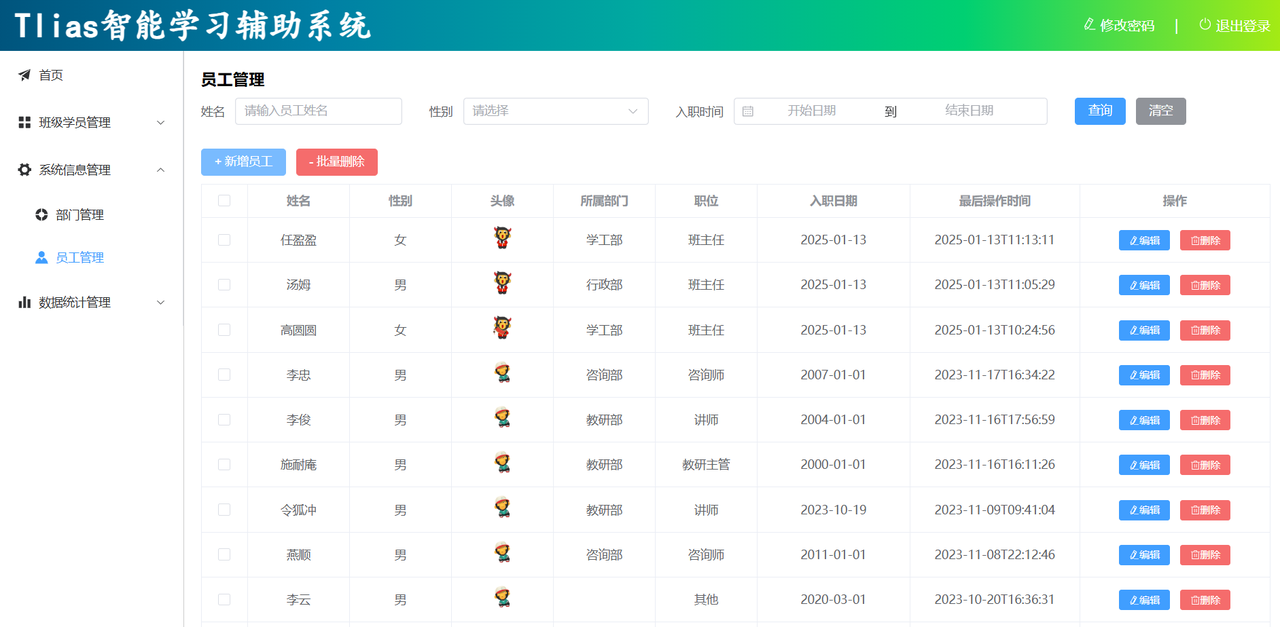

在这个案例中，我们主要完成 部门管理 和 员工管理 的功能开发。 而今天呢，我们先来完成部门管理的功能开发，而在完成部门管理的功能开发之前，先需要完成基础的准备工作。 所以今天的课程安排如下：

- 前后端分离开发

- 准备工作

- 页面布局

- Vue-Router

- 部门管理

## 前后端分离开发

> **补充｜接口契约。** 前后端分离的核心不是“两个目录”本身，而是双方围绕接口文档协作：请求方法、路径、参数、状态码和响应结构必须稳定。前端应处理加载中、空数据和失败提示，后端则保持错误响应格式一致。

在之前的课程中，我们介绍过，现在的企业项目开发有2种开发模式：前后台混合开发 和 前后台分离开发。

前后台混合开发，顾名思义就是前台后台代码混在一起开发。这种开发模式有如下缺点：

- 沟通成本高：后台人员发现前端有问题，需要找前端人员修改，前端修改成功，再交给后台人员使用

- 分工不明确：后台开发人员需要开发后台代码，也需要开发部分前端代码。很难培养专业人才

- 不便管理：所有的代码都在一个工程中

- 难以维护：前端代码更新，和后台无关，但是需要整个工程包括后台一起重新打包部署。

所以我们目前基本都是采用的前后台分离开发方式，如下图所示：

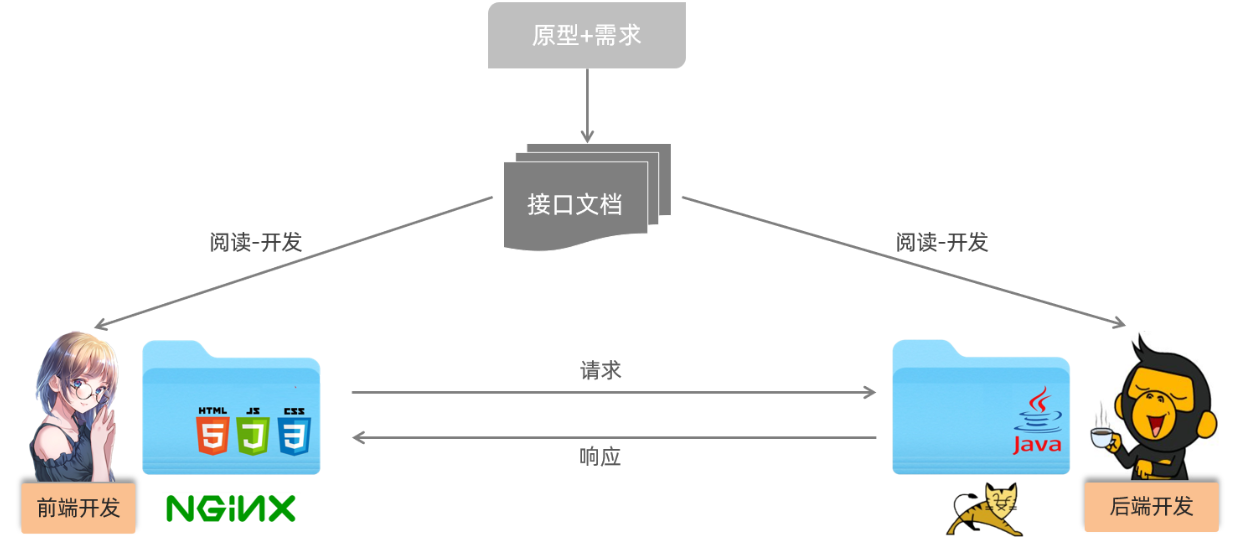

我们将原先的工程分为前端工程和后端工程这2个工程，然后前端工程交给专业的前端人员开发，后端工程交给专业的后端人员开发。

前端页面需要数据，可以通过发送异步请求，从后台工程获取。但是，我们前后台是分开来开发的，那么前端人员怎么知道后台返回数据的格式呢？后端人员开发，怎么知道前端人员需要的数据格式呢？

所以针对这个问题，我们前后台统一制定一套规范！我们前后台开发人员都需要遵循这套规范开发，这就是我们的 接口文档。接口文档有离线版和在线版本，接口文档示可以查询今天提供 资料/接口文档 里面的资料。

那么接口文档的内容怎么来的呢？是我们后台开发者根据产品经理提供的产品原型和需求文档所撰写出来的，产品原型示例可以参考今天提供资料/页面原型 里面的资料。

那么基于前后台分离开发的模式下，我们后台开发者开发一个功能的具体流程如何呢？如下图所示：

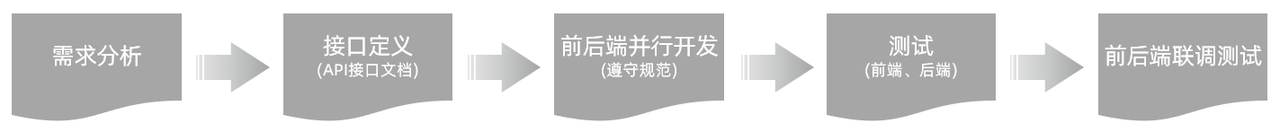

1. 需求分析：首先我们需要阅读需求文档，分析需求，理解需求。

1. 接口定义：查询接口文档中关于需求的接口的定义，包括地址，参数，响应数据类型等等

1. 前后台并行开发：各自按照接口文档进行开发，实现需求

1. 测试：前后台开发完了，各自按照接口文档进行测试

1. 前后段联调测试：前段工程请求后端工程，测试功能

## 页面布局

> **补充｜布局可维护性。** 菜单、顶部栏和主内容区适合拆成布局组件，业务页面只负责自己的数据和交互。使用 `router-view` 作为内容出口，避免把部门管理页面硬编码在布局组件中。

### 准备工作

1. 导入资料中准备的基础工程到VsCode。 【复制出来放在自己的工作目录下】

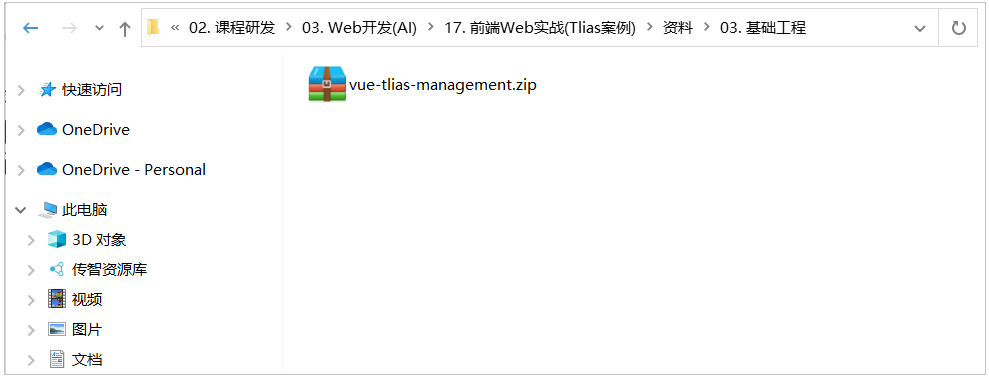

1. 启动前端项目，访问该项目

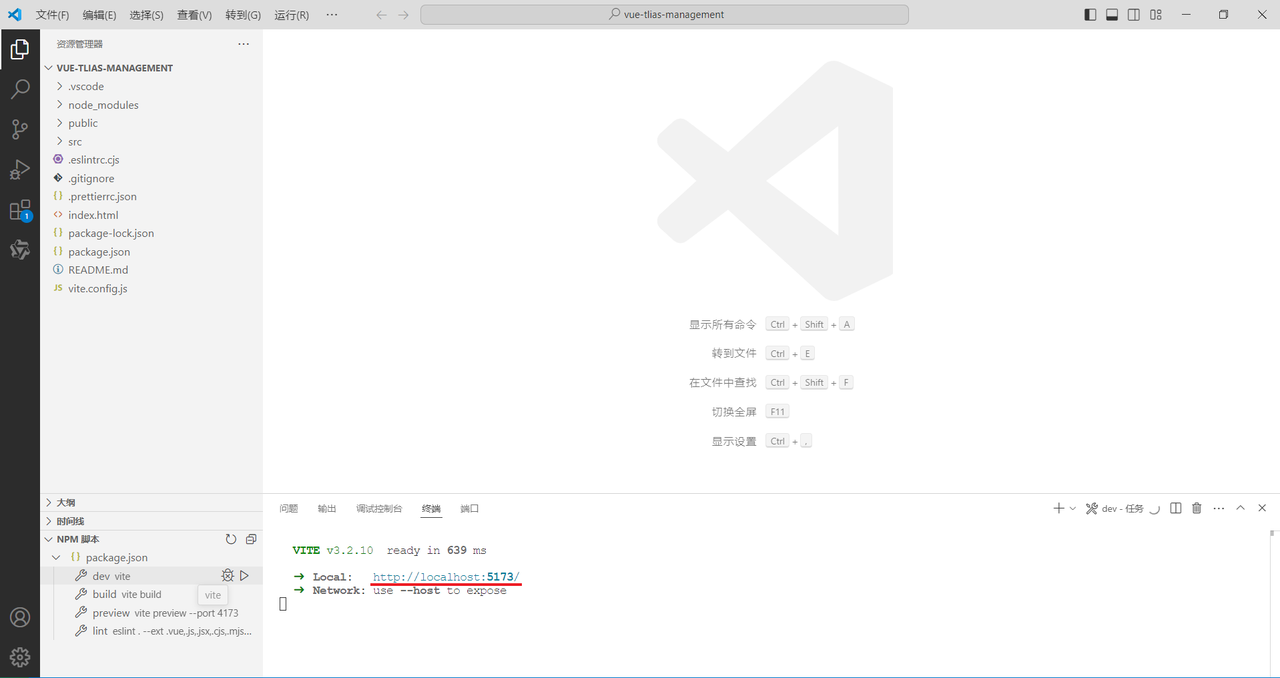

打开浏览器，访问 http://localhost:5173

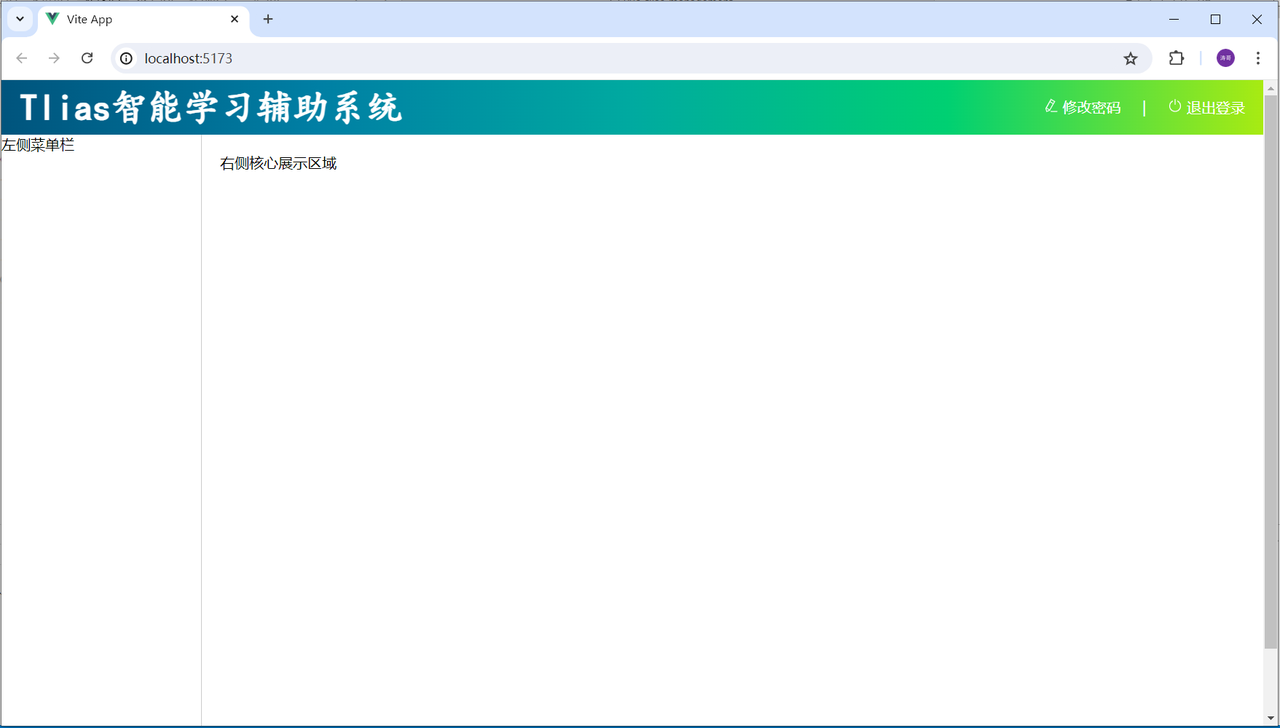

在提供的基础工程中，最基本的页面布局，已经准备好了。 我们通过页面原型可以看到页面的布局如下：

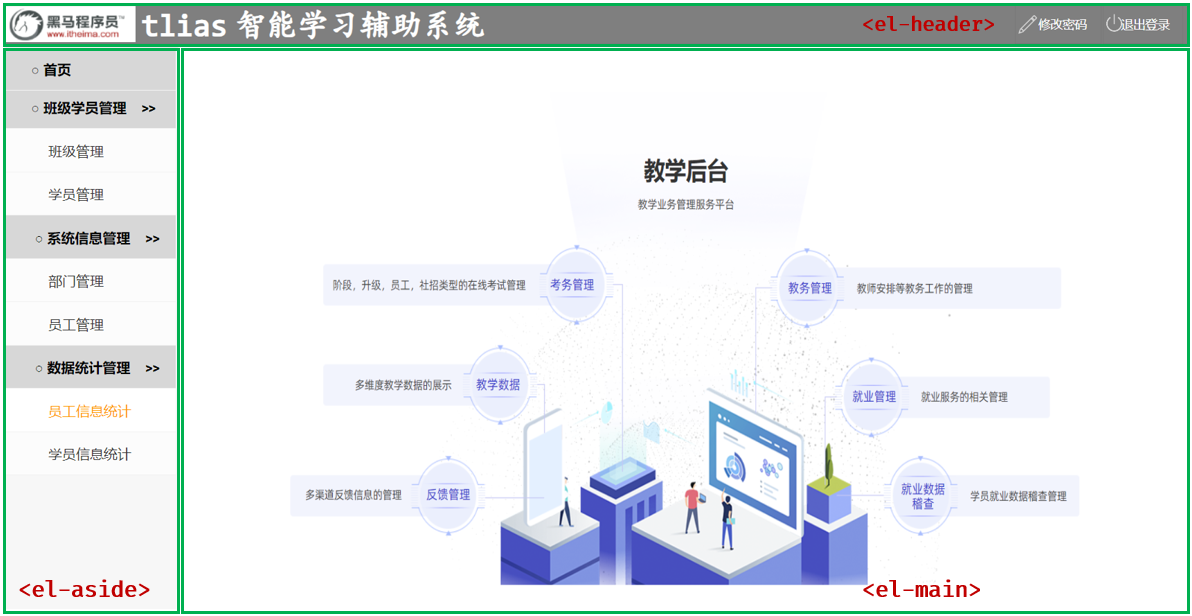

其实要实现这个页面布局，我们可以借助于 ElementPlus 中提供的 container 容器布局。

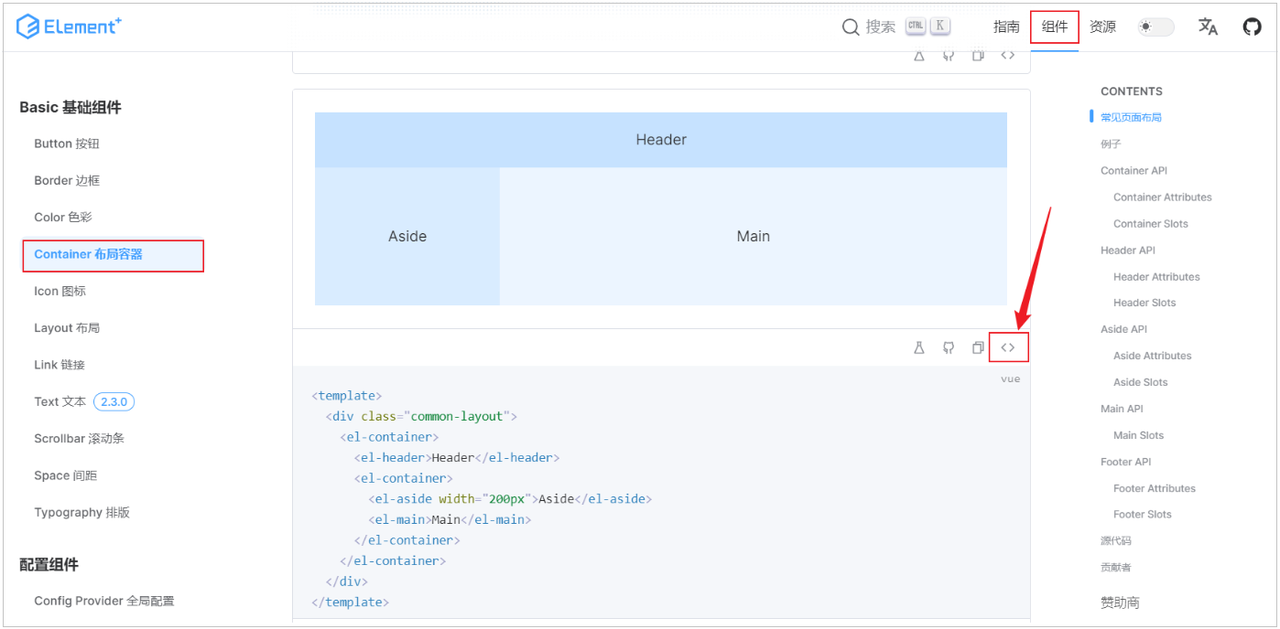

Container布局容器，用于布局的容器组件，方便快速搭建页面的基本结构：

<el-container>：外层容器。 当子元素中包含 <el-header> 或 <el-footer> 时，全部子元素会垂直上下排列， 否则会水平左右排列。

<el-header>：顶栏容器。

<el-aside>：侧边栏容器。

<el-main>：主要区域容器。

<el-footer>：底栏容器。

**讲义提示**

> 提示：当  <el-container> 子元素中包含  <el-header>  或  <el-footer>  时，全部子元素会垂直上下排列， 否则会水平左右排列。

### 左侧菜单布局

接下来，我们再来完成左侧菜单栏的制作。

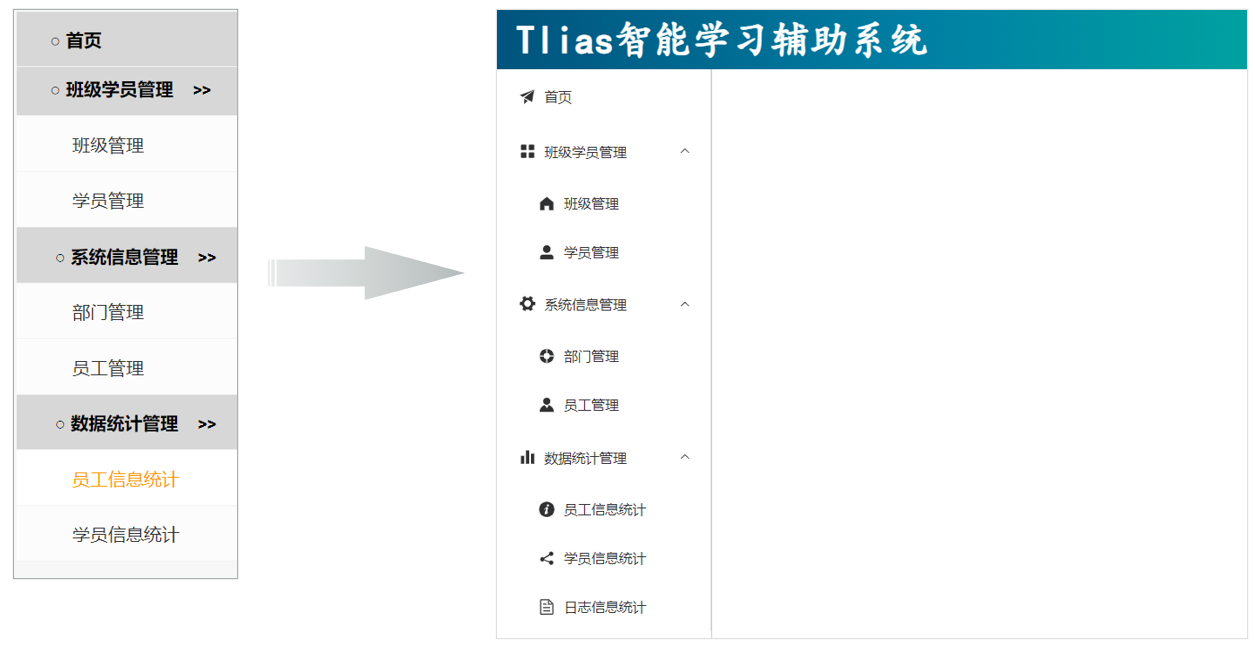

左侧菜单栏的制作，也不需要我们自己实现，其实在 ElementPlus 中已经提供了对应的菜单组件，我们可以直接参考【PS: 其实就是复制过来，参考页面原型和需求，将其改造成我们需要的样子就可以了】。

参考代码的出处:

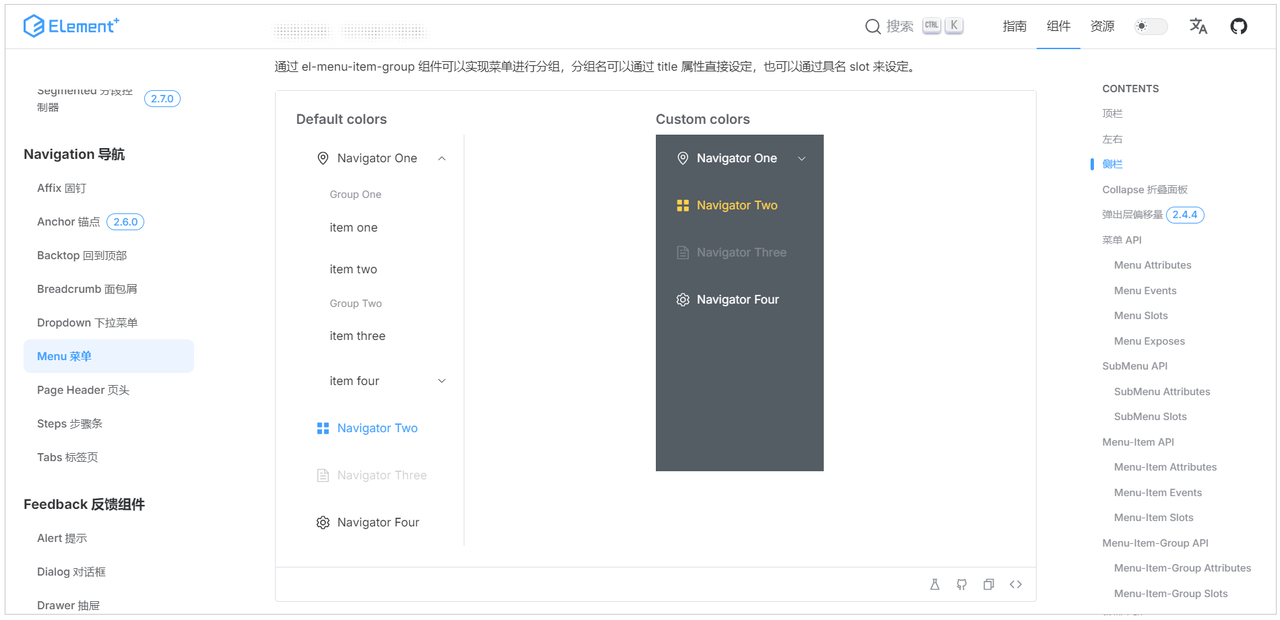

然后就可以参考其提供的源码，复制到我们的侧边栏部分 <el-aside> ... </el-aside>，然后根据我们案例的需要进行改造，改造成我们需要的样子即可。

最终左侧菜单栏的代码如下 ，大家可以直接导入到 views/layout/index.vue 的侧边栏区域 <el-aside> ... </el-aside>  ：

```html
<el-menu>
    <!-- 首页菜单 -->
    <el-menu-item index="/index">
      <el-icon><Promotion /></el-icon> 首页
    </el-menu-item>
    
    <!-- 班级管理菜单 -->
    <el-sub-menu index="/manage">
      <template #title>
        <el-icon><Menu /></el-icon> 班级学员管理
      </template>
      <el-menu-item index="/clazz">
        <el-icon><HomeFilled /></el-icon>班级管理
      </el-menu-item>
      <el-menu-item index="/stu">
        <el-icon><UserFilled /></el-icon>学员管理
      </el-menu-item>
    </el-sub-menu>
    
    <!-- 系统信息管理 -->
    <el-sub-menu index="/system">
      <template #title>
        <el-icon><Tools /></el-icon>系统信息管理
      </template>
      <el-menu-item index="/dept">
        <el-icon><HelpFilled /></el-icon>部门管理
      </el-menu-item>
      <el-menu-item index="/emp">
        <el-icon><Avatar /></el-icon>员工管理
      </el-menu-item>
    </el-sub-menu>
    
    <!-- 数据统计管理 -->
    <el-sub-menu index="/report">
      <template #title>
        <el-icon><Histogram /></el-icon>数据统计管理
      </template>
      <el-menu-item index="/empReport">
        <el-icon><InfoFilled /></el-icon>员工信息统计
      </el-menu-item>
      <el-menu-item index="/stuReport">
        <el-icon><Share /></el-icon>学员信息统计
      </el-menu-item>
      <el-menu-item index="/log">
        <el-icon><Document /></el-icon>日志信息统计
      </el-menu-item>
    </el-sub-menu>
</el-menu>
```

最终，浏览器打开的效果如下：

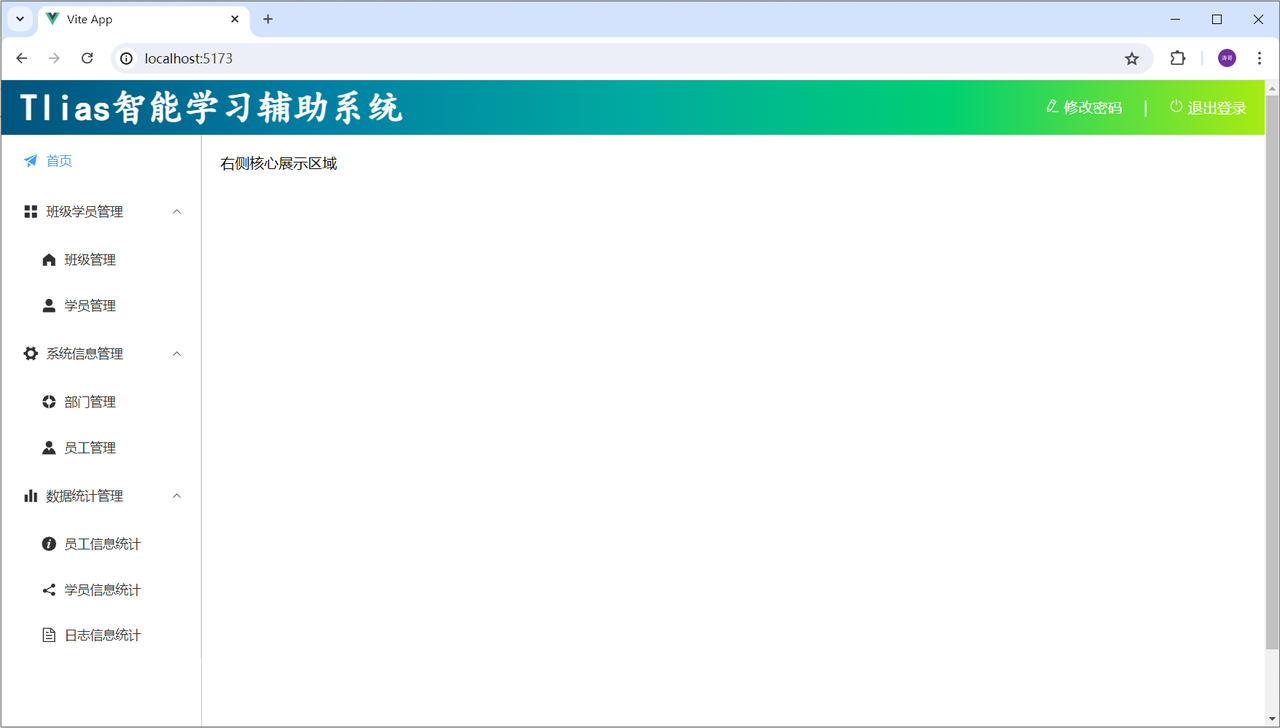

到目前为止，views/layout/index.vue 中的整体内容如下：

```html
<script setup>

</script>

<template>
  <div class="common-layout">
    <el-container>
      <!-- Header 区域 -->
      <el-header class="header">
        <span class="title">Tlias智能学习辅助系统</span>
        <span class="right_tool">
          <a href="">
            <el-icon><EditPen /></el-icon> 修改密码 &nbsp;&nbsp;&nbsp; |  &nbsp;&nbsp;&nbsp;
          </a>
          <a href="">
            <el-icon><SwitchButton /></el-icon> 退出登录
          </a>
        </span>
      </el-header>
      
      <el-container>
        <!-- 左侧菜单 -->
        <el-aside width="200px" class="aside">
          
          <el-menu>
            <!-- 首页菜单 -->
            <el-menu-item index="/index">
              <el-icon><Promotion /></el-icon> 首页
            </el-menu-item>
            
            <!-- 班级管理菜单 -->
            <el-sub-menu index="/manage">
              <template #title>
                <el-icon><Menu /></el-icon> 班级学员管理
              </template>
              <el-menu-item index="/clazz">
                <el-icon><HomeFilled /></el-icon>班级管理
              </el-menu-item>
              <el-menu-item index="/stu">
                <el-icon><UserFilled /></el-icon>学员管理
              </el-menu-item>
            </el-sub-menu>
            
            <!-- 系统信息管理 -->
            <el-sub-menu index="/system">
              <template #title>
                <el-icon><Tools /></el-icon>系统信息管理
              </template>
              <el-menu-item index="/dept">
                <el-icon><HelpFilled /></el-icon>部门管理
              </el-menu-item>
              <el-menu-item index="/emp">
                <el-icon><Avatar /></el-icon>员工管理
              </el-menu-item>
            </el-sub-menu>

            <!-- 数据统计管理 -->
            <el-sub-menu index="/report">
              <template #title>
                <el-icon><Histogram /></el-icon>数据统计管理
              </template>
              <el-menu-item index="/empReport">
                <el-icon><InfoFilled /></el-icon>员工信息统计
              </el-menu-item>
              <el-menu-item index="/stuReport">
                <el-icon><Share /></el-icon>学员信息统计
              </el-menu-item>
              <el-menu-item index="/log">
                <el-icon><Document /></el-icon>日志信息统计
              </el-menu-item>
            </el-sub-menu>
          </el-menu>
          
        </el-aside>
        
        <el-main>
          右侧核心展示区域
        </el-main>
      </el-container>
      
    </el-container>
  </div>
</template>

<style scoped>
.header {
  background-image: linear-gradient(to right, #00547d, #007fa4, #00aaa0, #00d072, #a8eb12);
}

.title {
  color: white;
  font-size: 40px;
  font-family: 楷体;
  line-height: 60px;
  font-weight: bolder;
}

.right_tool{
  float: right;
  line-height: 60px;
}

a {
  color: white;
  text-decoration: none;
}

.aside {
  width: 220px;
  border-right: 1px solid #ccc;
  height: 730px;
}
</style>
```

目前，我们点击左侧的菜单，右侧主区域展示的内容，还不能做到动态变化。 那应该如何做到动态变化呢 ？

要解决这个问题，就需要通过VueRouter来解决。

## VueRouter

> **补充｜路由刷新。** 浏览器直接访问嵌套路由时，开发服务器需要把未知路径回退到 `index.html`；生产部署还要配置同样的 history fallback。导航菜单应使用 `router-link` 或 `router.push`，避免手动拼接 URL。

### 介绍

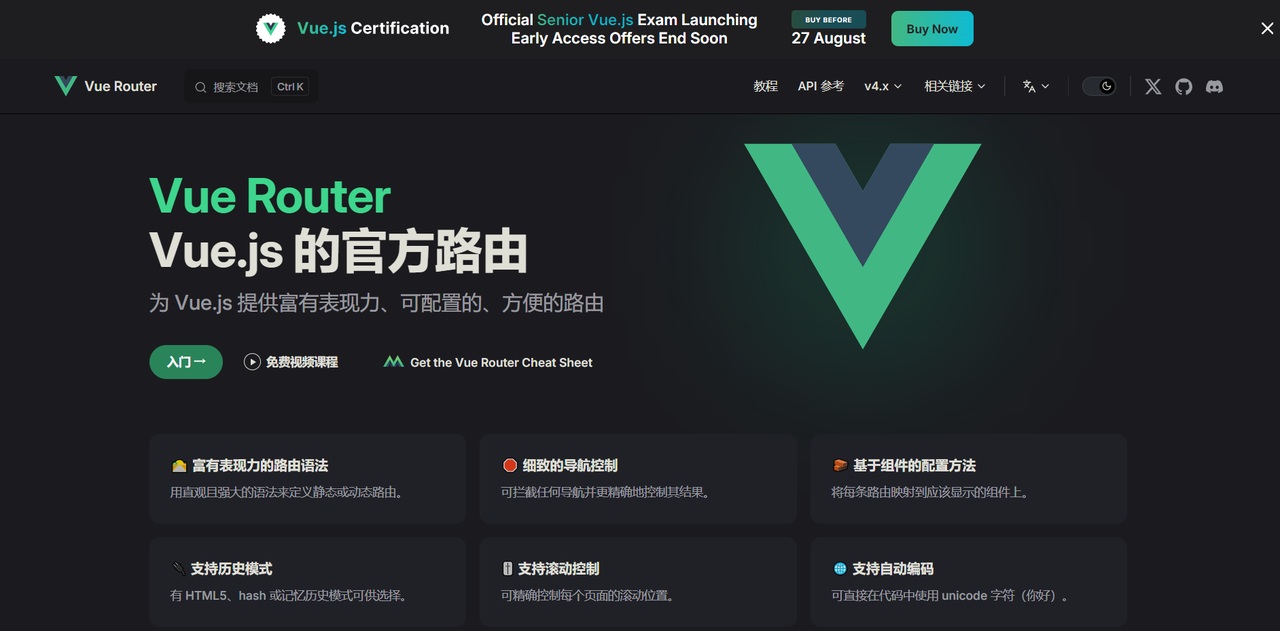

- Vue Router：Vue的官方路由。 为Vue提供富有表现力、可配置的、方便的路由。

- Vue中的路由，主要定义的是路径与组件之间的对应关系。

比如，我们打开一个网站，点击左侧菜单，地址栏的地址发生变化。 地址栏地址一旦发生变化，在主区域显示对应的页面组件。

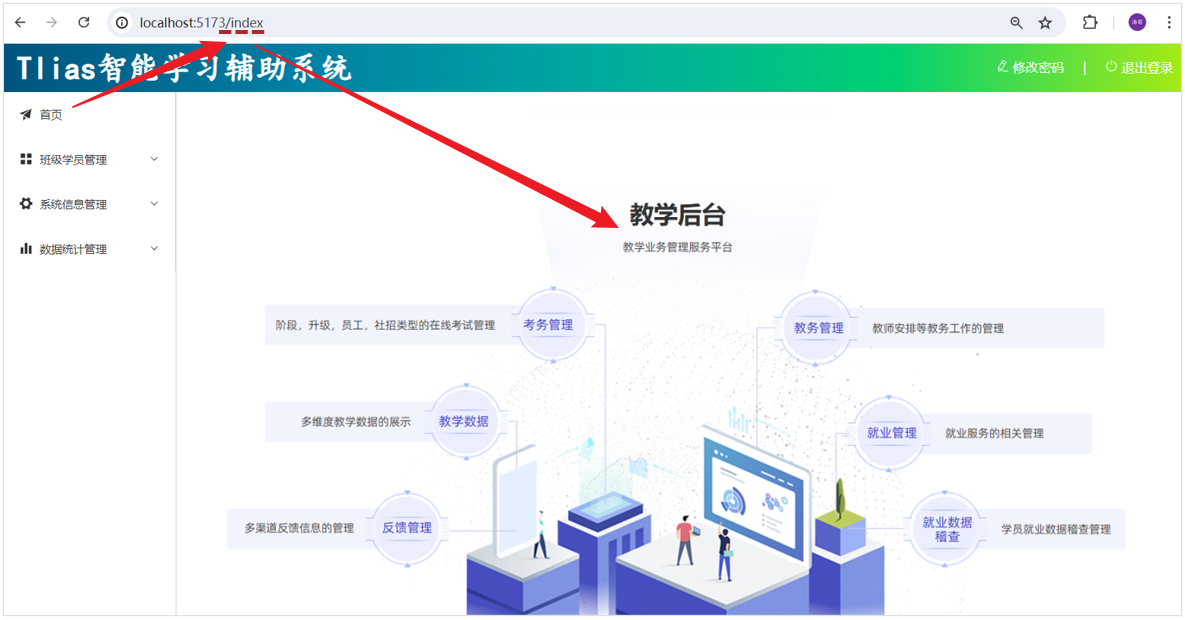

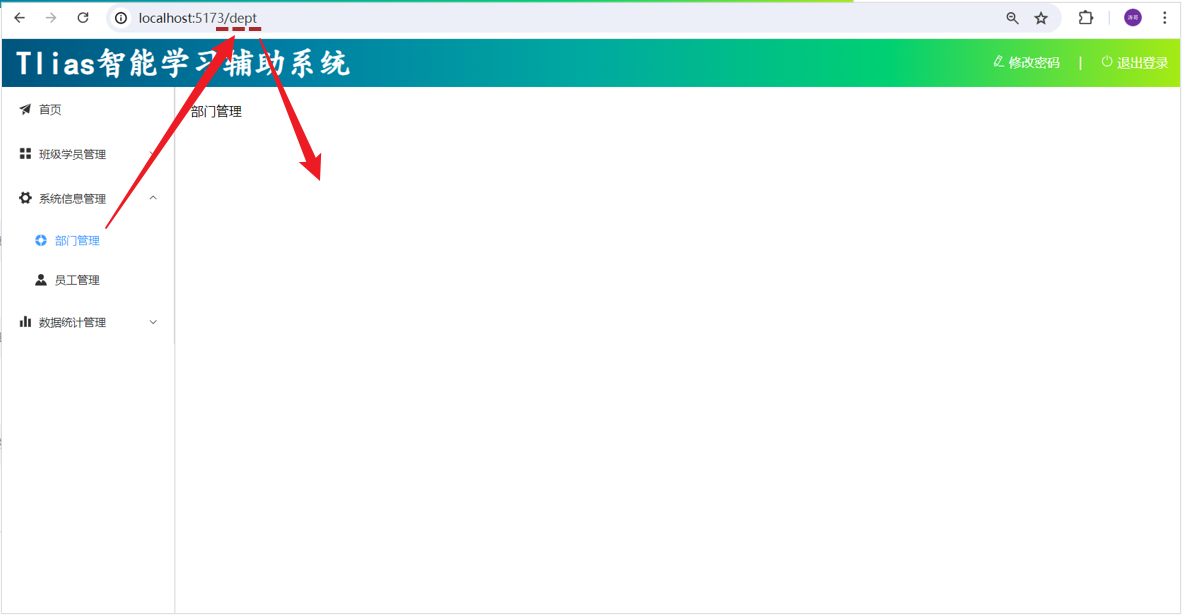

VueRouter主要由以下三个部分组成，如下所示：

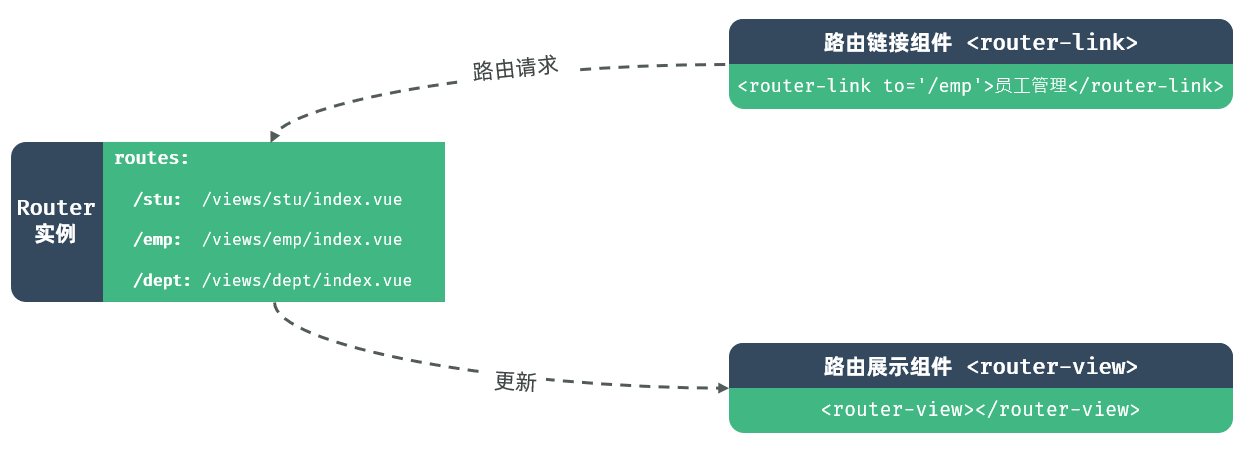

- VueRouter：路由器类，根据路由请求在路由视图中动态渲染选中的组件

- <router-link>：请求链接组件，浏览器会解析成<a>

- <router-view>：动态视图组件，用来渲染展示与路由路径对应的组件

### 基础路由配置

1). 在 views/layout/index.vue 中，调整代码，具体调整位置如下：

- 在左侧菜单栏的 <el-menu> 标签上添加 router 属性，这会让 Element Plus 的 <el-menu> 组件自动根据路由来激活对应的菜单项。

- 使用 <router-view> 组件来渲染根据路由动态变化的内容。

- 确保每个 <el-menu-item> 的 index 属性值与你想要导航到的路径相匹配。

```html
<script setup>
// 无需额外导入，因为我们只是使用了 Element Plus 和 Vue Router 的基本功能
</script>

<template>
  <div class="common-layout">
    <el-container>
      <!-- Header 区域 -->
      <el-header class="header">
        <span class="title">Tlias智能学习辅助系统</span>
        <span class="right_tool">
          <a href="">
            <el-icon><EditPen /></el-icon> 修改密码 &nbsp;&nbsp;&nbsp; |  &nbsp;&nbsp;&nbsp;
          </a>
          <a href="">
            <el-icon><SwitchButton /></el-icon> 退出登录
          </a>
        </span>
      </el-header>
      
      <el-container>
        <!-- 左侧菜单 -->
        <el-aside width="200px" class="aside">

          <el-menu router>
            <!-- 首页菜单 -->
            <el-menu-item index="/index">
              <el-icon><Promotion /></el-icon> 首页
            </el-menu-item>
            
            <!-- 班级管理菜单 -->
            <el-sub-menu index="/manage">
              <template #title>
                <el-icon><Menu /></el-icon> 班级学员管理
              </template>
              <el-menu-item index="/clazz">
                <el-icon><HomeFilled /></el-icon>班级管理
              </el-menu-item>
              <el-menu-item index="/stu">
                <el-icon><UserFilled /></el-icon>学员管理
              </el-menu-item>
            </el-sub-menu>
            
            <!-- 系统信息管理 -->
            <el-sub-menu index="/system">
              <template #title>
                <el-icon><Tools /></el-icon>系统信息管理
              </template>
              <el-menu-item index="/dept">
                <el-icon><HelpFilled /></el-icon>部门管理
              </el-menu-item>
              <el-menu-item index="/emp">
                <el-icon><Avatar /></el-icon>员工管理
              </el-menu-item>
            </el-sub-menu>

            <!-- 数据统计管理 -->
            <el-sub-menu index="/report">
              <template #title>
                <el-icon><Histogram /></el-icon>数据统计管理
              </template>
              <el-menu-item index="/report/emp">
                <el-icon><InfoFilled /></el-icon>员工信息统计
              </el-menu-item>
              <el-menu-item index="/report/stu">
                <el-icon><Share /></el-icon>学员信息统计
              </el-menu-item>
              <el-menu-item index="/log">
                <el-icon><Document /></el-icon>日志信息统计
              </el-menu-item>
            </el-sub-menu>
          </el-menu>
        </el-aside>
        
        <!-- 主展示区域 -->
        <el-main>
          <router-view></router-view>
        </el-main>
      </el-container>
    </el-container>
  </div>
</template>

<style scoped>
.header {
  background-image: linear-gradient(to right, #00547d, #007fa4, #00aaa0, #00d072, #a8eb12);
}

.title {
  color: white;
  font-size: 40px;
  font-family: 楷体;
  line-height: 60px;
  font-weight: bolder;
}

.right_tool{
  float: right;
  line-height: 60px;
}

a {
  color: white;
  text-decoration: none;
}

.aside {
  width: 220px;
  border-right: 1px solid #ccc;
  height: 730px;
}
</style>
```

2). 在 router/index.js 中配置请求路径与组件之间的关系。

```javascript
import { createRouter, createWebHistory} from 'vue-router';

import IndexView from '@/views/index/index.vue';
import ClazzView from '@/views/clazz/index.vue';
import StuView from '@/views/stu/index.vue';
import DeptView from '@/views/dept/index.vue';
import EmpView from '@/views/emp/index.vue';
import EmpReportView from '@/views/report/emp/index.vue';
import StuReportView from '@/views/report/stu/index.vue';
import LogView from '@/views/log/index.vue';
import LoginView from '@/views/login/index.vue';

const routes = [
  { path: '/index', component: IndexView },
  { path: '/clazz', component: ClazzView },
  { path: '/stu', component: StuView },
  { path: '/dept', component: DeptView },
  { path: '/emp', component: EmpView },
  { path: '/report/emp', component: EmpReportView },
  { path: '/report/stu', component: StuReportView },
  { path: '/log', component: LogView },
  { path: '/login', component: LoginView },
];

const router = createRouter({
  history: createWebHistory(),
  routes,
});

export default router;
```

经过这么两步操作之后，我们就可以看到，在页面上，点击左侧菜单，右侧主展示区域，就会显示出对应的页面了。

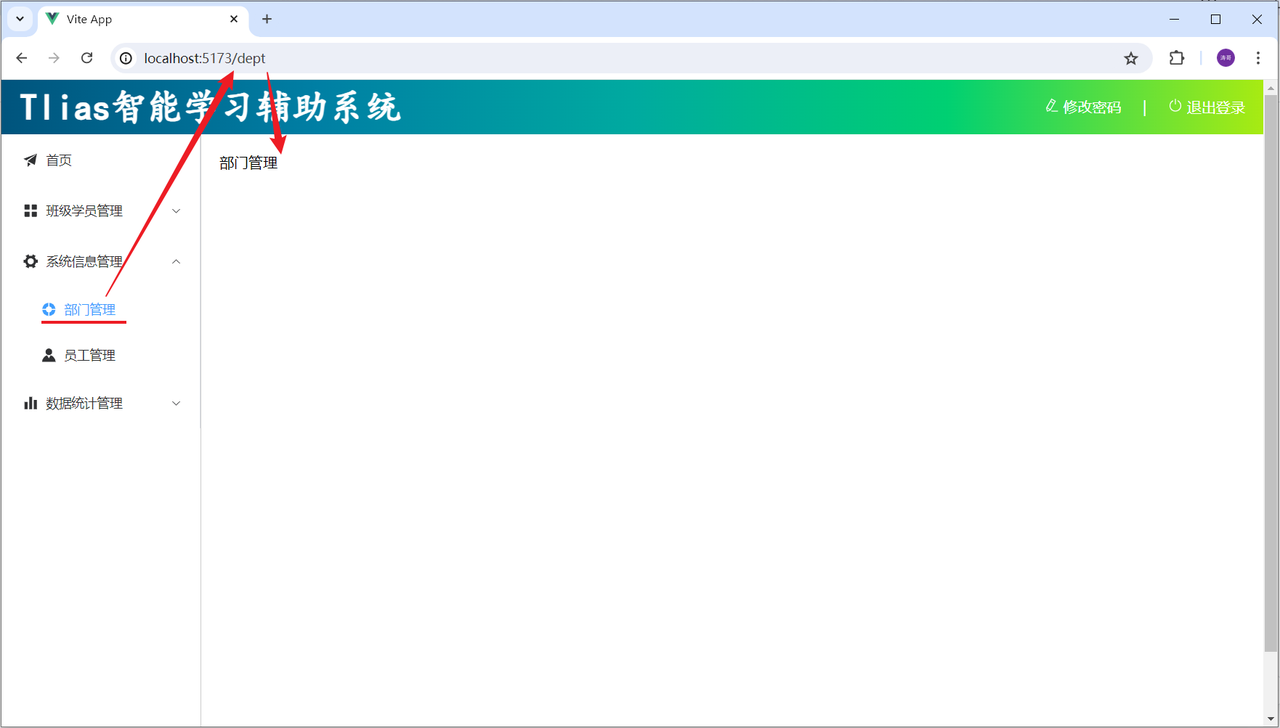

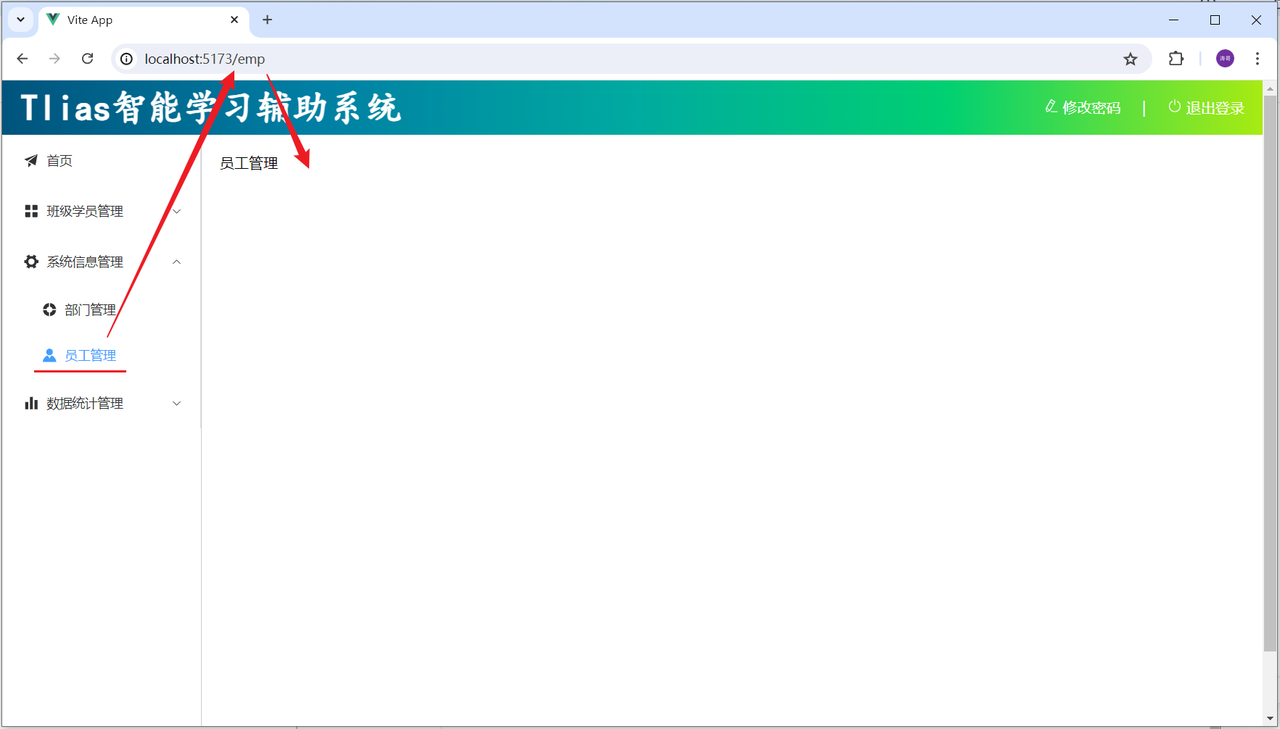

那要完成这个功能效果，我们就需要用到Vue生态中的路由 Vue-Router。

### 完善路由配置

上述我们只是完成了最基本的路由配置。 并经过测试我们发现，如果我们访问 /login 路径，会发现，登录页面是在layout页面中嵌套展示的，这肯定是不合适的。

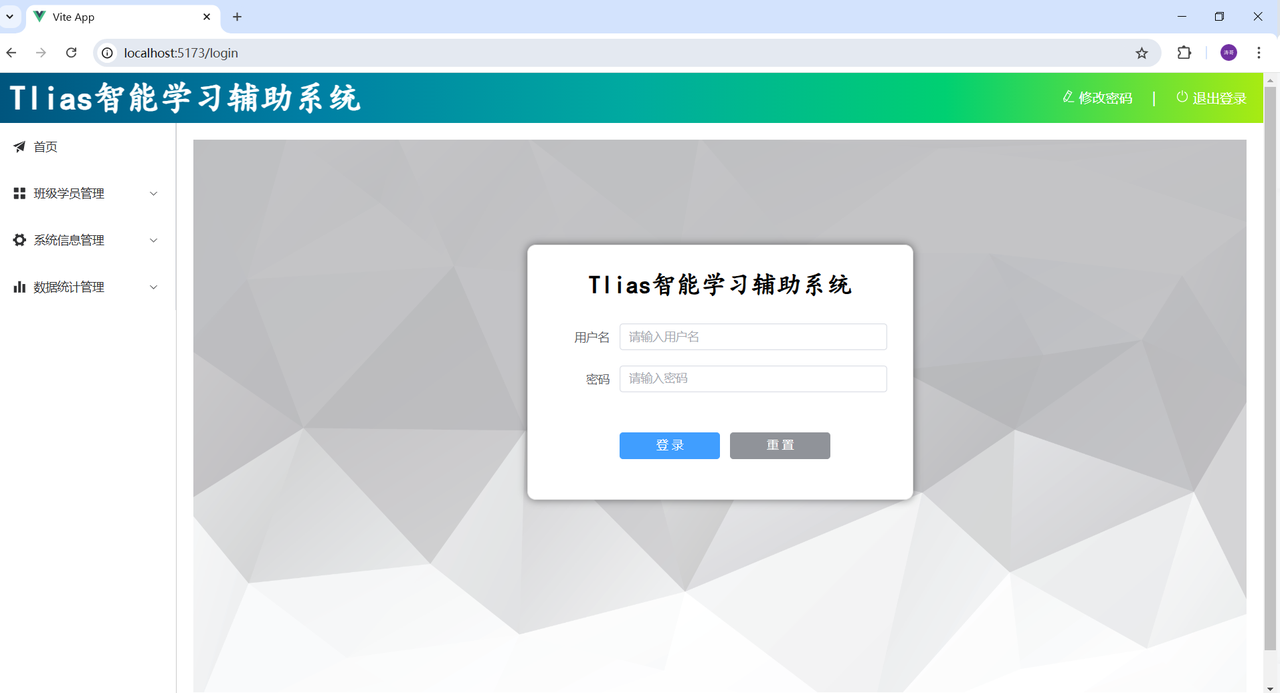

那接下来，我们就来优化一下路由的配置。最终配置形式如下，在 router/index.js 中做如下配置：

```javascript
import { createRouter, createWebHistory } from 'vue-router'

import IndexView from '@/views/index/index.vue'
import ClazzView from '@/views/clazz/index.vue'
import DeptView from '@/views/dept/index.vue'
import EmpView from '@/views/emp/index.vue'
import LogView from '@/views/log/index.vue'
import StuView from '@/views/stu/index.vue'
import EmpReportView from '@/views/report/emp/index.vue'
import StuReportView from '@/views/report/stu/index.vue'
import LayoutView from '@/views/layout/index.vue'
import LoginView from '@/views/login/index.vue'

const router = createRouter({
  history: createWebHistory(import.meta.env.BASE_URL),
  routes: [
    {
     path: '/', 
     name: '',
     component: LayoutView,
     redirect: '/index', //重定向
     children: [
      {path: 'index', name: 'index', component: IndexView},
      {path: 'clazz', name: 'clazz', component: ClazzView},
      {path: 'stu', name: 'stu', component: StuView},
      {path: 'dept', name: 'dept', component: DeptView},
      {path: 'emp', name: 'emp', component: EmpView},
      {path: 'log', name: 'log', component: LogView},
      {path: 'empReport', name: 'empReport', component: EmpReportView},
      {path: 'stuReport', name: 'stuReport', component: StuReportView},
     ]
    },
    {path: '/login', name: 'login', component: LoginView}
  ]
})

export default router
```

具体的执行访问流程如下:

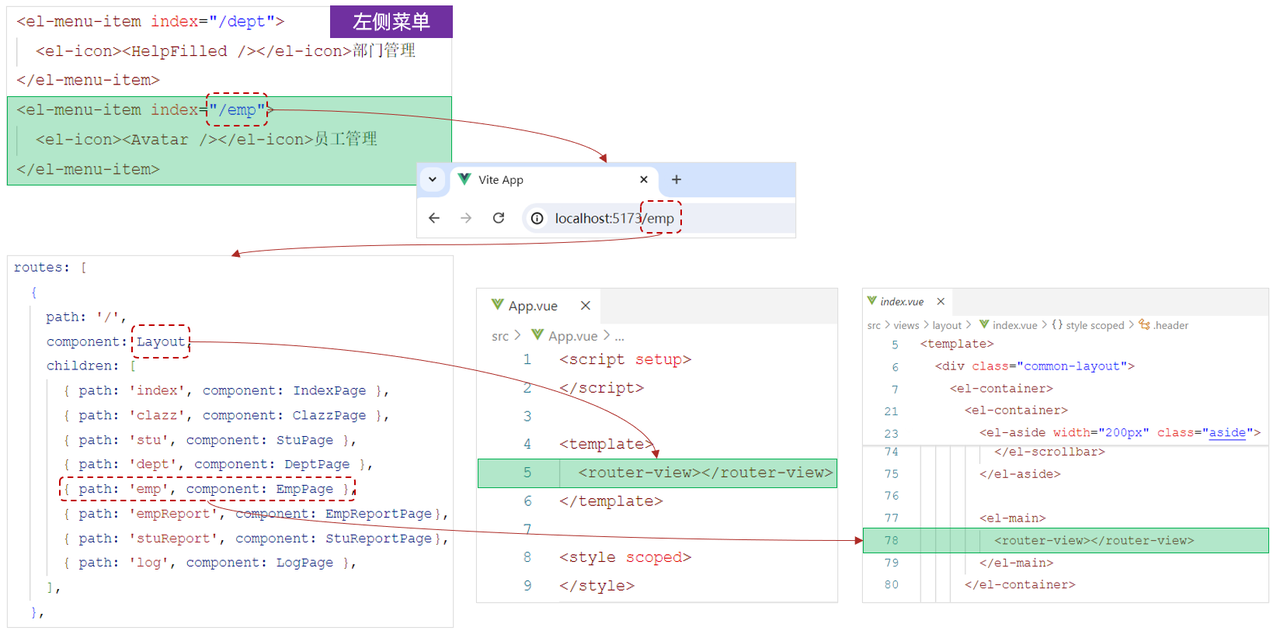

1. 当点击左侧菜单栏的员工管理菜单时，最终地址栏会访问路径 /emp 。

1. 此时VueRouter，会自动的到所配置的路由表（router/index.js）中，查找与该路径对应的组件，并展示在路由展示组件<router-view> 对应的位置中。

## 部门管理

> **补充｜状态边界。** 列表数据、弹窗开关、当前编辑对象和提交状态应分开管理。提交期间禁用按钮可以避免重复请求；接口成功后再关闭弹窗并刷新列表，失败时保留表单内容方便修正。

部门管理的页面内容，写在 src/views/dept/index.vue 中。

### 部门列表

> **补充｜列表健壮性。** 查询函数应统一处理 loading、成功、空数组和异常状态。不要把接口返回对象直接当作数组使用，先根据项目约定读取 `data` 字段，并在开发者工具中确认真实响应结构。

#### 基本布局

首先，根据页面原型、需求说明、接口文档，先完成页面的基本布局 。 可以参考 ElementPlus 中的组件，拷贝过来适当做一个改造。

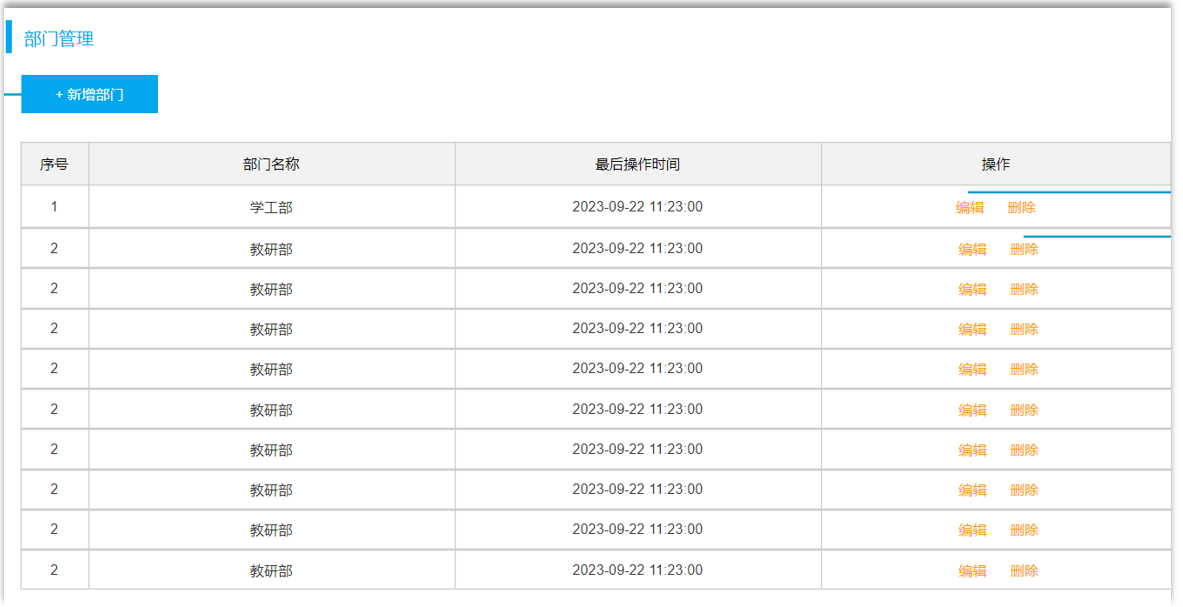

我们先来完成页面的基本布局。

部门管理组件 src/views/dept/index.vue 具体的页面布局代码如下：

```html
<script setup>
import { ref } from 'vue';

// 示例数据
const deptList= ref([
  { id: 1, name: '学工部', createTime: '2024-09-01T23:06:29', updateTime: '2024-09-01T23:06:29' },
  { id: 2, name: '教研部', createTime: '2024-09-01T23:06:29', updateTime: '2024-09-01T23:06:29' }
]);

// 编辑部门 - 根据ID查询回显数据
const handleEdit = (id) => {
  console.log(`Edit item with ID ${id}`);
  // 在这里实现编辑功能
};

// 删除部门 - 根据ID删除部门
const handleDelete = (id) => {
  console.log(`Delete item with ID ${id}`);
  // 在这里实现删除功能
};
</script>

<template>
  <h1>部门管理</h1>

  <!-- 按钮靠页面右侧显示 -->
  <el-button type="primary" @click="handleEdit" style="float: right;"> + 新增部门</el-button> <br><br>

  <el-table :data="deptList" border style="width: 100%;">
    <el-table-column type="index" label="序号" width="100" align="center"/>
    <el-table-column prop="name" label="部门名称" width="300" align="center"/>
    <el-table-column prop="updateTime" label="最后修改时间" width="300" align="center"/>
    <el-table-column fixed="right" label="操作" align="center">
      <template #default="scope">
        <el-button size="small" @click="handleEdit(scope.row.id)">修改</el-button>
        <el-button size="small" type="danger" @click="handleDelete(scope.row.id)">删除</el-button>
      </template>
    </el-table-column>
  </el-table>
  
</template>

<style scoped>

</style>
```

表格中每一列展示的属性 prop 都是根据接口文档来的，接口文档返回什么样的数据，我们就安装对应的数据格式进行解析。

最终页面效果，展示如下：

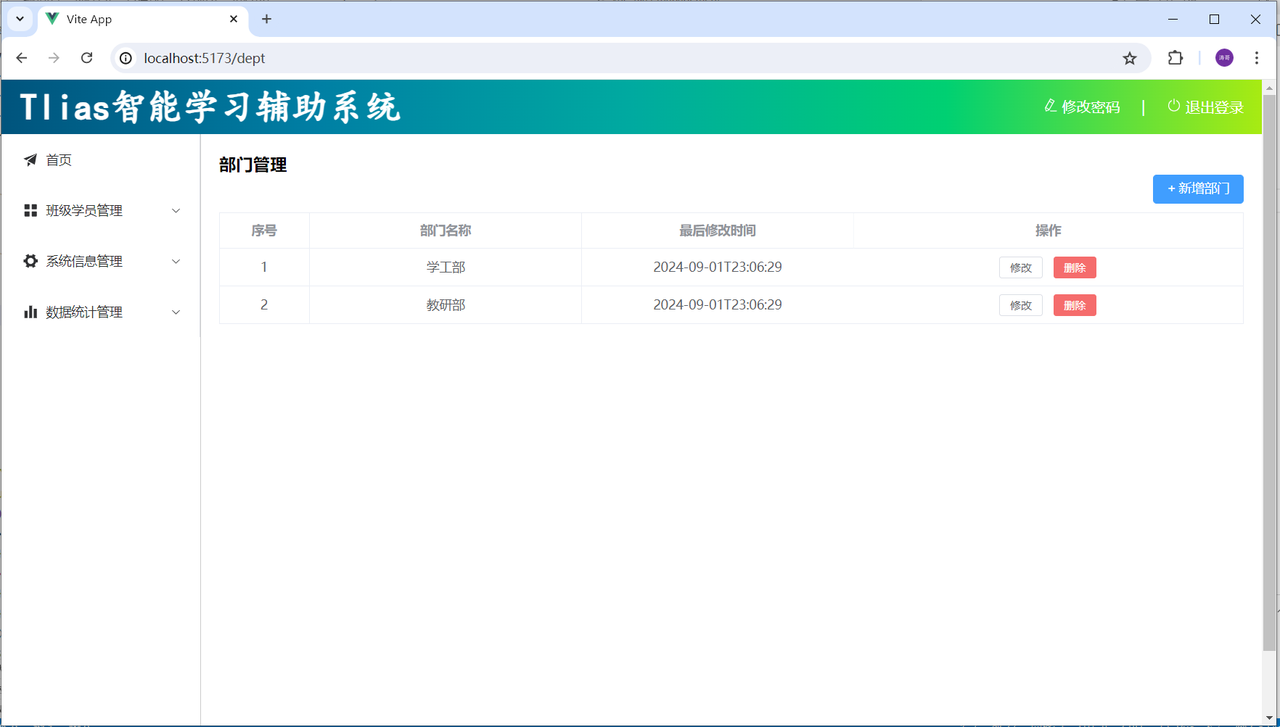

#### 加载数据

根据需求，需要在新增、修改、删除部门之后，加载最新的部门数据。 在打开页面之后，也需要自动加载部门数据。 那接下来，我们就需要基于axios发送异步请求，动态获取数据。

需要在 src/views/dept/index.vue 中增加如下代码，在页面加载完成发送异步请求（https://apifoxmock.com/m1/3128855-1224313-default/depts），动态加载的Axios。

```html
<script setup>
import {ref, onMounted} from 'vue'
import axios from 'axios'

//声明列表展示数据
let deptList= ref([])

//动态加载数据-查询部门
const queryAll = async () => {
  const result = await axios.get('https://apifoxmock.com/m1/3128855-1224313-default/depts')
  deptList.value = result.data.data
}

//钩子函数
onMounted(() => {
  queryAll()
})

// 编辑部门 - 根据ID查询回显数据
const handleEdit = (id) => {
  console.log(`Edit item with ID ${id}`);
  // 在这里实现编辑功能
};

// 删除部门 - 根据ID删除部门
const handleDelete = (id) => {
  console.log(`Delete item with ID ${id}`);
  // 在这里实现删除功能
};
</script>
```

添加代码后，最终  src/views/dept/index.vue  完整代码如下：

```html
<script setup>
import {ref, onMounted} from 'vue'
import axios from 'axios'

//声明列表展示数据
let deptList= ref([])

//动态加载数据-查询部门
const queryAll = async () => {
  const result = await axios.get('https://apifoxmock.com/m1/3161925-0-default/depts')
  deptList.value = result.data.data
}

//钩子函数
onMounted(() => {
  queryAll()
})

// 编辑部门 - 根据ID查询回显数据
const handleEdit = (id) => {
  console.log(`Edit item with ID ${id}`);
  // 在这里实现编辑功能
};

// 删除部门 - 根据ID删除部门
const handleDelete = (id) => {
  console.log(`Delete item with ID ${id}`);
  // 在这里实现删除功能
};
</script>

<template>
  <h1>部门管理</h1>

  <!-- 按钮靠页面右侧显示 -->
  <el-button type="primary" @click="handleEdit" style="float: right;"> + 新增部门</el-button> <br><br>

  <el-table :data="deptList" border style="width: 100%;">
    <el-table-column type="index" label="序号" width="100" align="center"/>
    <el-table-column prop="name" label="部门名称" width="300" align="center"/>
    <el-table-column prop="updateTime" label="最后修改时间" width="300" align="center"/>
    <el-table-column fixed="right" label="操作" align="center">
      <template #default="scope">
        <el-button size="small" @click="handleEdit(scope.row.id)">修改</el-button>
        <el-button size="small" type="danger" @click="handleDelete(scope.row.id)">删除</el-button>
      </template>
    </el-table-column>
  </el-table>
</template>

<style scoped>

</style>
```

页面效果如下，页面一加载，马上就会查询出所有的部门数据：

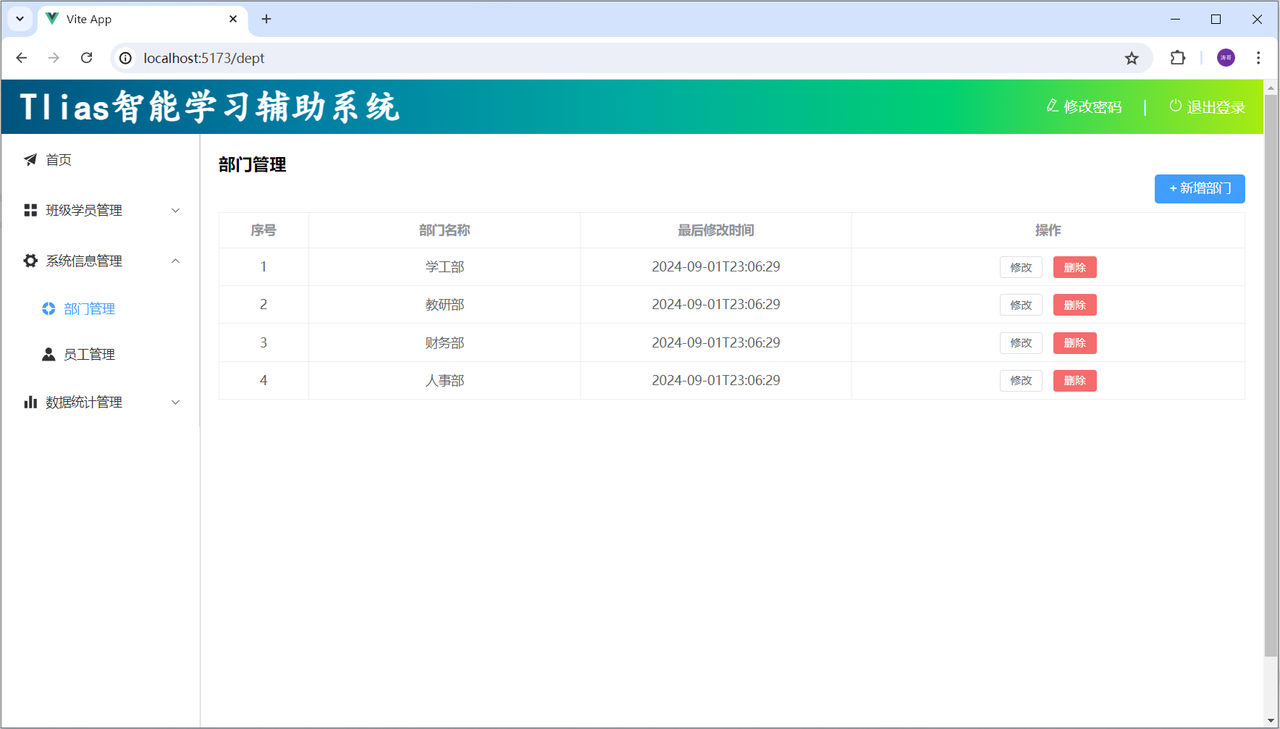

我们可以看到数据可以正常的查询出来，并展示在页面中。

思考：直接在Vue组件中，基于axios发送异步请求，存在什么问题？

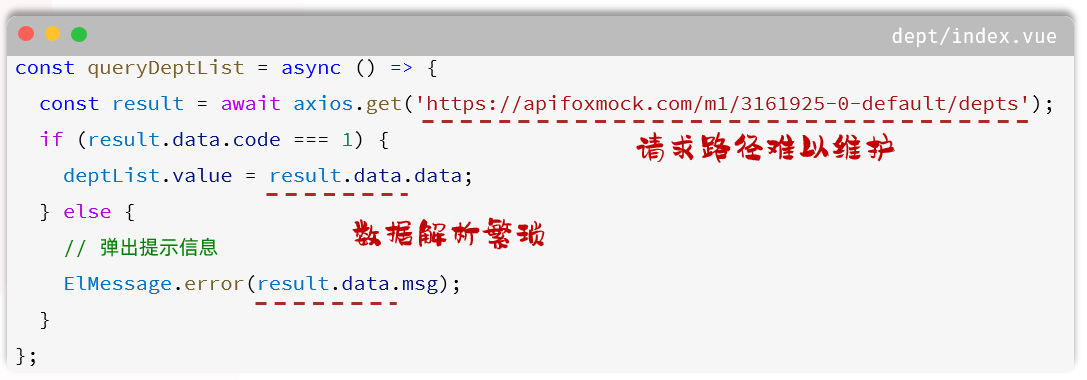

我们刚才在完成部门列表查询时，是直接基于axios发送异步请求，直接将接口的请求地址放在组件文件 .vue 中。 而如果开发一个大型的项目，组件文件可能会很多很多很多，如果前端开发完毕，进行前后端联调测试了，需要修改请求地址，那么此时，就需要找到每一个 .vue 文件，然后挨个修改。 所以上述的代码，虽然实现了动态加载数据的功能。 但是存在以下问题：

- 请求路径难以维护

- 数据解析繁琐

#### 程序优化

1). 为了解决上述问题，我们在前端项目开发时，通常会定义一个请求处理的工具类  - src/utils/request.js 。 在这个工具类中，对axios进行了封装。 具体代码如下：

```javascript
import axios from 'axios'

//创建axios实例对象
const request = axios.create({
  baseURL: '/api',
  timeout: 600000
})

//axios的响应 response 拦截器
request.interceptors.response.use(
  (response) => { //成功回调
    return response.data
  },
  (error) => { //失败回调
    return Promise.reject(error)
  }
)

export default request
```

2). 而与服务端进行异步交互的逻辑，通常会按模块，封装在一个单独的API中，如：src/api/dept.js

```javascript
import request from "@/utils/request"

//列表查询
export const queryAllApi = () => request.get('/depts')
```

3). 修改 src/views/dept/index.vue 中的代码

现在就不需要每次直接调用axios发送异步请求了，只需要将我们定义的对应模块的API导入进来，就可以直接使用了。

```javascript
<script setup>
import {ref, onMounted} from 'vue'
import {queryAllApi} from '@/api/dept'

//声明列表展示数据
let deptList= ref([])

//动态加载数据-查询部门
const queryAll = async () => {
  const result = await queryAllApi()
  deptList.value = result.data
}

//钩子函数
onMounted(() => {
  queryAll()
})

// 编辑部门 - 根据ID查询回显数据
const handleEdit = (id) => {
  console.log(`Edit item with ID ${id}`);
  // 在这里实现编辑功能
};

// 删除部门 - 根据ID删除部门
const handleDelete = (id) => {
  console.log(`Delete item with ID ${id}`);
  // 在这里实现删除功能
};
</script>
```

做完上面这三步之后，我们打开浏览器发现，并不能访问到接口数据。原因是因为，目前请求路径不对。

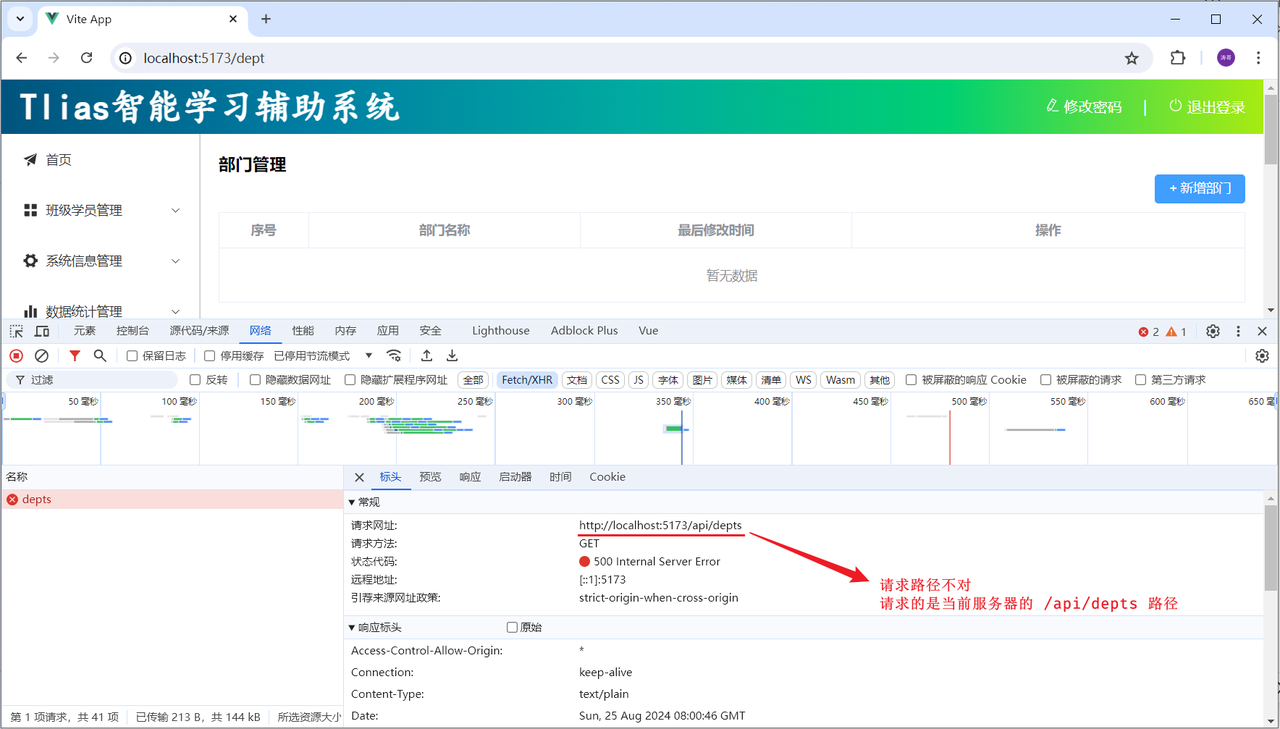

4). 在 vite.config.js 中配置前端请求服务器的信息

在服务器中配置代理proxy的信息，并在配置代理时，执行目标服务器。 以及url路径重写的规则。

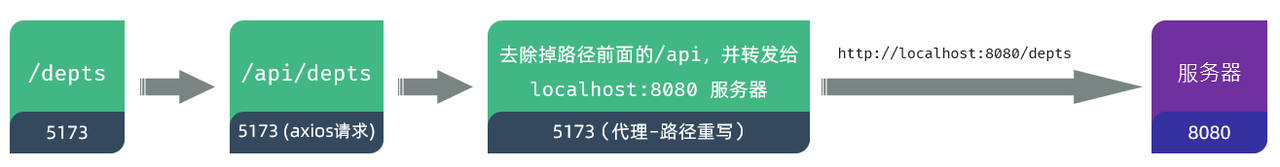

```javascript
import { fileURLToPath, URL } from 'node:url'

import { defineConfig } from 'vite'
import vue from '@vitejs/plugin-vue'
import vueJsx from '@vitejs/plugin-vue-jsx'

// https://vitejs.dev/config/
export default defineConfig({
  plugins: [
    vue(),
    vueJsx(),
  ],
  resolve: {
    alias: {
      '@': fileURLToPath(new URL('./src', import.meta.url))
    }
  },
  server: {
    proxy: {
      '/api': {
        target: 'http://localhost:8080',
        secure: false,
        changeOrigin: true,
        rewrite: (path) => path.replace(/^\/api/, ''),
      }
    }
  }
})
```

添加内容为，绿色阴影部分的代码。

然后，我们就可以启动服务器端的程序（将之前开发的服务端程序启动起来测试一下 ），进行测试了（【注意：测试时, 记得将令牌校验的过滤器及拦截器, 以及记录日志的AOP程序 全部注释】）。

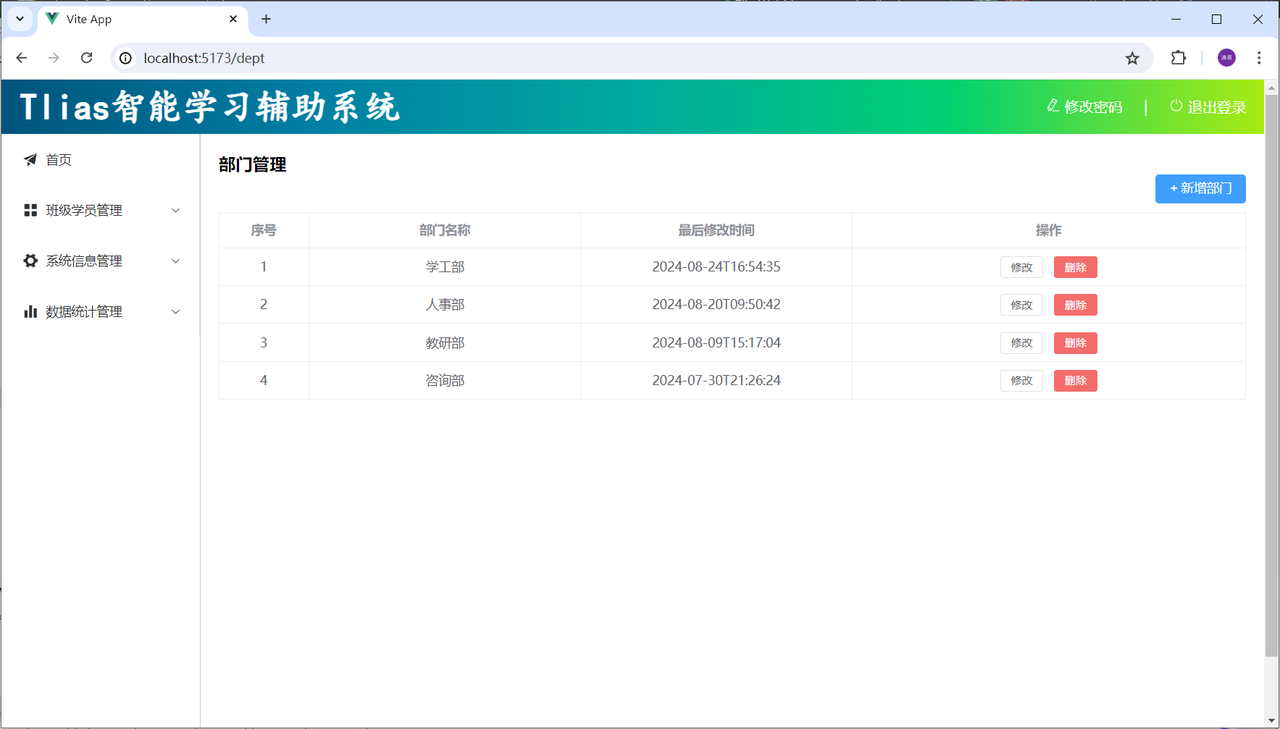

### 新增部门

> **补充｜表单复用。** 新增和编辑通常可以复用同一个 Dialog 与表单，通过 `formTitle`、`submit` 方法和当前 ID 区分模式。打开新增弹窗时要重置表单和校验状态，避免上一次编辑内容残留。

#### 功能实现

接下来，我们再来完成新增部门的功能实现。

新增部门和编辑部门，可以同用一个Dialog对话框。而这个对话框中，主要包括两个ElementPlus中的组件，分别为：Dialog对话框组件，Form表单组件。

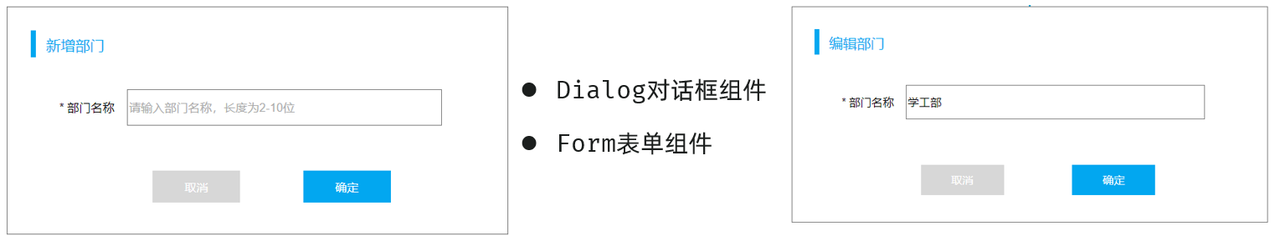

1). 在 src/views/dept/index.vue 中完成页面布局，并编写交互逻辑，完成数据绑定。

完整代码如下：

```html
<script setup>
import { ref, onMounted } from 'vue'
import { ElMessage } from 'element-plus'
import { queryAllApi, addDeptApi } from '@/api/dept'

// 声明列表展示数据
let deptList= ref([])

// 动态加载数据 - 查询部门
const queryAll = async () => {
  const result = await queryAllApi()
  deptList.value = result.data
}

// 钩子函数
onMounted(() => {
  queryAll()
})

// 编辑部门 - 根据ID查询回显数据
const handleEdit = (id) => {
  console.log(`Edit item with ID ${id}`);
  // 在这里实现编辑功能
};

// 删除部门 - 根据ID删除部门
const handleDelete = (id) => {
  console.log(`Delete item with ID ${id}`);
  // 在这里实现删除功能
};


const formTitle = ref('')
//新增部门
const add = () => {
  formTitle.value = '新增部门'
  showDialog.value = true
  deptForm.value = {name: ''}
}

// 新增部门对话框的状态
const showDialog = ref(false)
// 表单数据
const deptForm = ref({name: ''})
// 表单验证规则
const formRules = ref({
  name: [
    { required: true, message: '请输入部门名称', trigger: 'blur' },
    { min: 2, max: 10, message: '长度在 2 到 10 个字符', trigger: 'blur' }
  ]
})

// 表单标签宽度
const formLabelWidth = ref('120px')
// 表单引用
const deptFormRef = ref(null)

// 重置表单
const resetForm = () => {
  deptFormRef.value.resetFields()
}

// 提交表单
const save = async () => {
  await deptFormRef.value.validate(async valid => {
    if (!valid) return
    // 提交表单
    const result = await addDeptApi(deptForm.value)
    if(result.code){
      ElMessage.success('操作成功')
      // 关闭对话框
      showDialog.value = false
      // 重置表单
      resetForm()
      // 重新加载数据
      queryAll()
    }else {
      ElMessage.error(result.msg)
    }
  })
}
</script>

<template>
  <h1>部门管理</h1>

  <!-- 按钮靠页面右侧显示 -->
  <el-button type="primary" @click="add()" style="float: right;"> + 新增部门</el-button> <br><br>

  <!-- 数据展示表格 -->
  <el-table :data="deptList" border style="width: 100%;">
    <el-table-column type="index" label="序号" width="100" align="center"/>
    <el-table-column prop="name" label="部门名称" width="300" align="center"/>
    <el-table-column prop="updateTime" label="最后修改时间" width="300" align="center"/>
    <el-table-column fixed="right" label="操作" align="center">
      <template #default="scope">
        <el-button size="small" @click="handleEdit(scope.row.id)">修改</el-button>
        <el-button size="small" type="danger" @click="handleDelete(scope.row.id)">删除</el-button>
      </template>
    </el-table-column>
  </el-table>

  <!-- 新增部门的对话框 -->
  <el-dialog v-model="showDialog" :title="formTitle" width="30%" @close="resetForm">
    <el-form :model="deptForm" :rules="formRules" ref="deptFormRef">
      <el-form-item label="部门名称" prop="name" label-width="80px">
        <el-input v-model="deptForm.name" autocomplete="off"></el-input>
      </el-form-item>
    </el-form>

    <template #footer>
      <span class="dialog-footer">
        <el-button @click="showDialog = false">取消</el-button>
        <el-button type="primary" @click="save">确定</el-button>
      </span>
    </template>
  </el-dialog>

</template>

<style scoped>

</style>
```

2). 在 src/api/dept.js 中增加如下代码

```javascript
//添加部门
export const addDeptApi = (data) => request.post('/depts', data)
```

目前  src/api/dept.js  文件中完整代码如下:

```javascript
import request from '@/utils/request'

//查询全部部门
export const queryAllApi = () => request.get('/depts')

//添加部门
export const addDeptApi = (data) => request.post('/depts', data)
```

打开浏览器进行测试，效果如下：

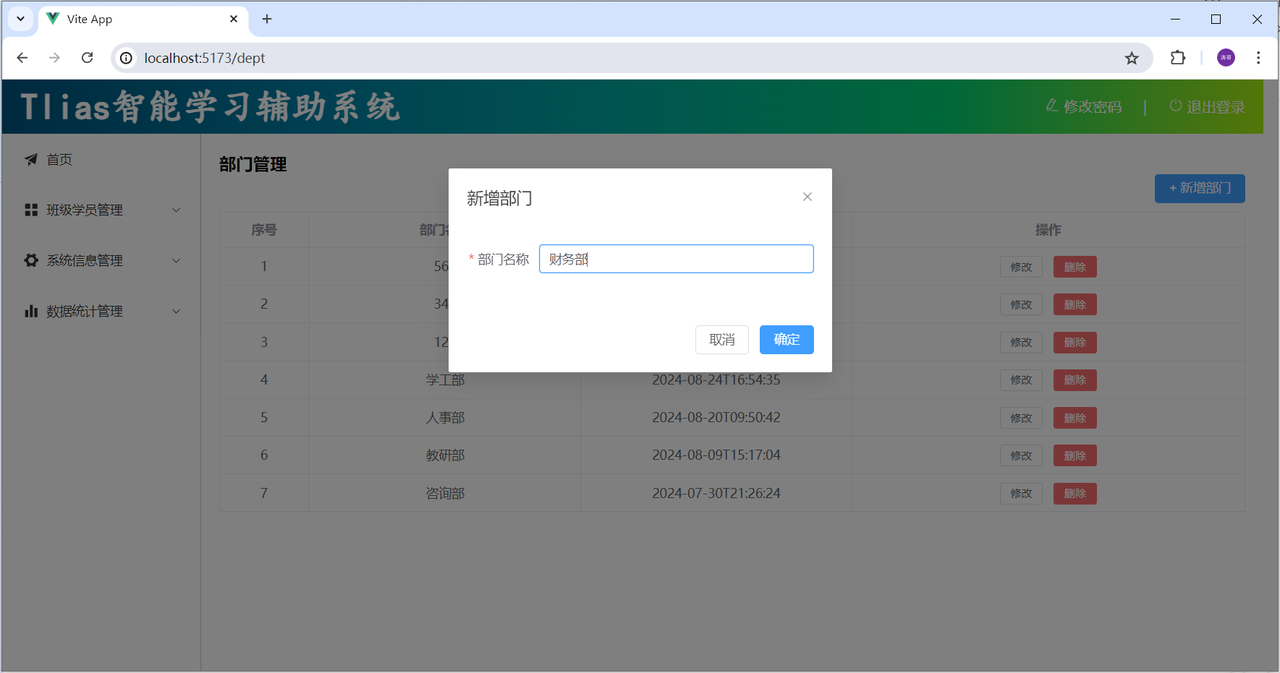

点击保存之后，就会将数据保存到数据库，并重新查询出最新的数据，展示在页面中。

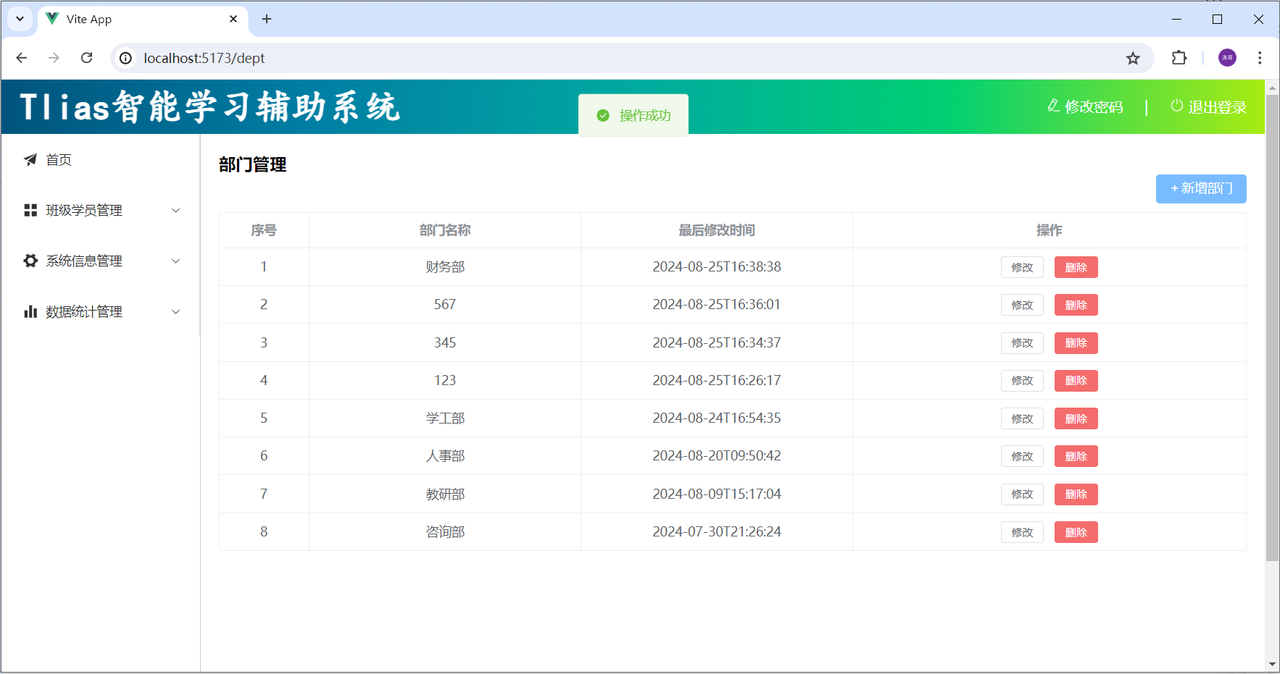

#### 表单校验

Form 组件允许你验证用户的输入是否符合规范，来帮助你找到和纠正错误。Form 组件提供了表单验证的功能，只需为 rules 属性传入约定的验证规则，并将 form-Item 的 prop 属性设置为需要验证的特殊键值即可。

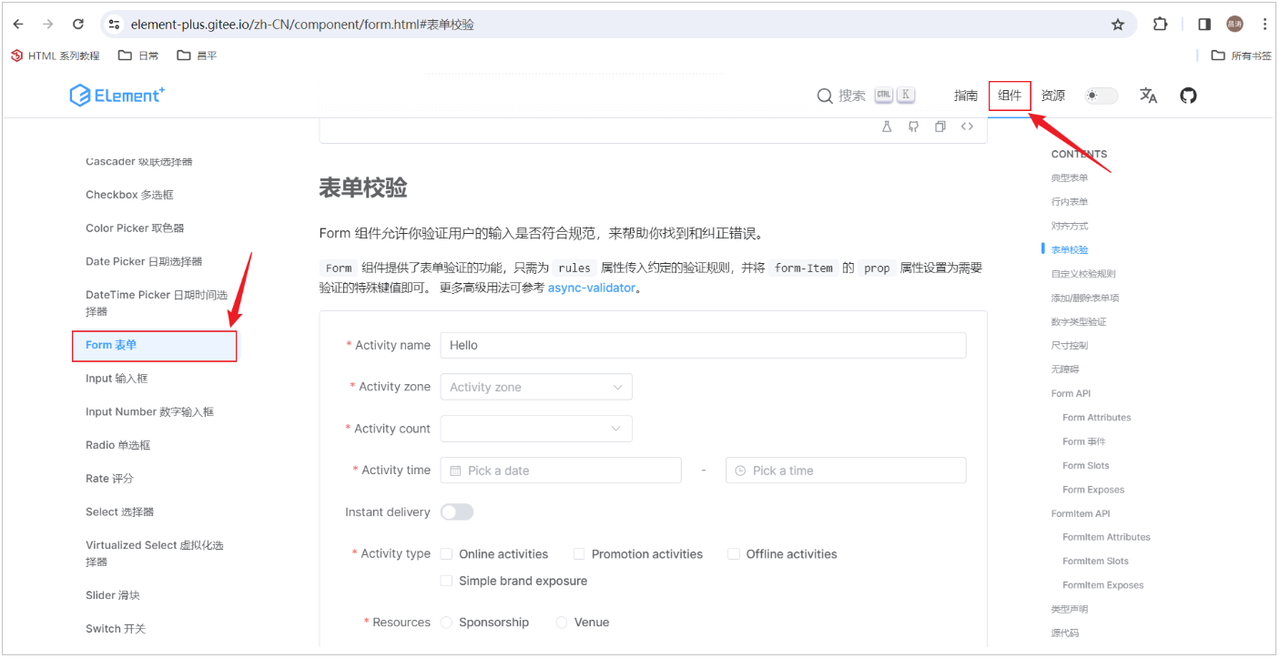

操作步骤：

- 通过ref属性注册元素的引用。

- 定义表单校验规则，通过rules属性与表单绑定，并通过prop属性绑定对应的表单项。

- 表单提交时，校验表单，校验通过，则允许提交表单。

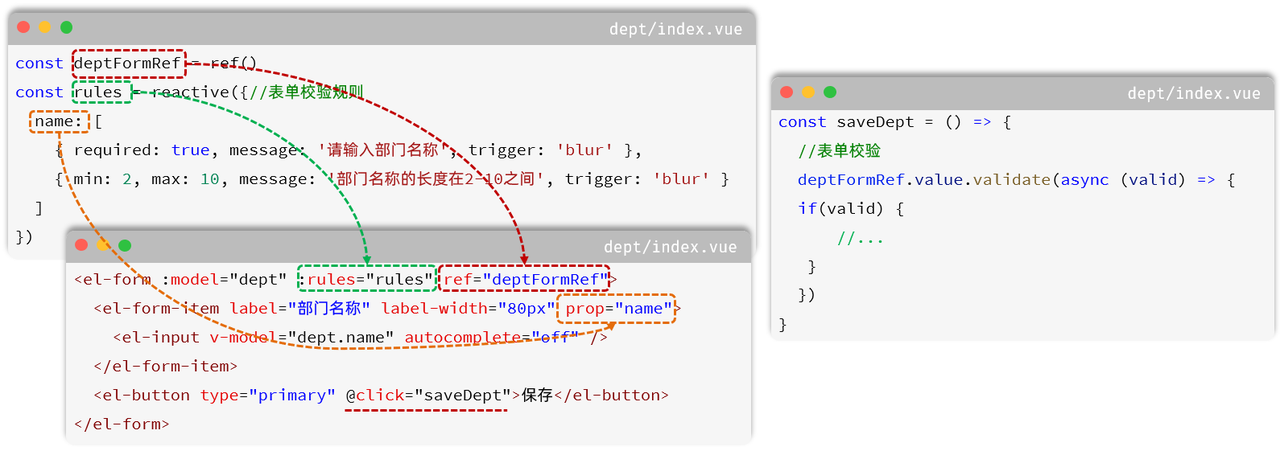

### 修改部门

> **补充｜回显与并发。** 编辑前根据行数据填充表单；若需要再次查询详情，应在打开弹窗时处理请求失败。提交时可携带版本号或更新时间解决多人同时编辑造成的覆盖问题。

对于修改操作，通常会分为两步进行：

1. 查询回显

1. 保存修改

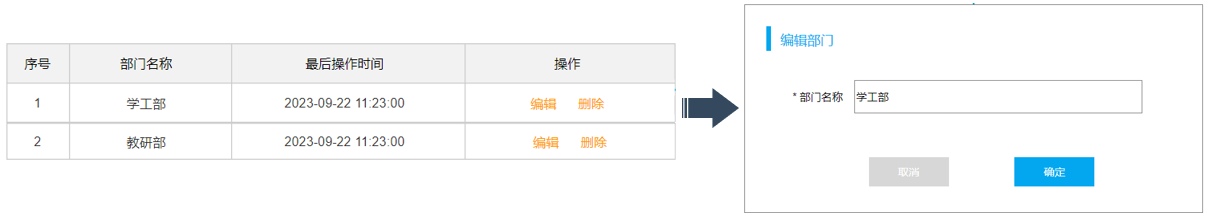

交互逻辑：

1. 点击 编辑 按钮，根据ID进行查询，弹出对话框，完成页面回显展示。（查询回显）

1. 点击 确定 按钮，保存修改后的数据，完成数据更新操作。（保存修改）

#### 查询回显

1). 在 src/api/dept.js 中定义根据id查询的请求

```javascript
//根据ID查询
export const queryInfoApi = (id) => request.get(`/depts/${id}`)
```

2). 在 src/views/dept/index.vue 中添加根据ID查询回显的逻辑

为修改按钮绑定事件 <template></template>:

```html
<el-button size="small" @click="handleEdit(scope.row.id)">修改</el-button>
```

在 <script> </script> 添加JS逻辑：

```javascript
// 编辑部门 - 根据ID查询回显数据
const handleEdit = async (id) => {
  console.log(`Edit item with ID ${id}`);
  formTitle.value = '修改部门'
  showDialog.value = true
  deptForm.value = {name: ''}

  const result = await queryInfoApi(id)
  if(result.code){
    deptForm.value = result.data
  }
};
```

到目前为止，完整的  src/views/dept/index.vue 代码如下：

```html
<script setup>
import { ref, onMounted } from 'vue'
import { ElMessage } from 'element-plus'
import { queryAllApi, addDeptApi, queryInfoApi } from '@/api/dept'

// 声明列表展示数据
let deptList= ref([])

// 动态加载数据 - 查询部门
const queryAll = async () => {
  const result = await queryAllApi()
  deptList.value = result.data
}

// 钩子函数
onMounted(() => {
  queryAll()
})

// 编辑部门 - 根据ID查询回显数据
const handleEdit = async (id) => {
  console.log(`Edit item with ID ${id}`);
  formTitle.value = '修改部门'
  showDialog.value = true
  deptForm.value = {name: ''}

  const result = await queryInfoApi(id)
  if(result.code){
    deptForm.value = result.data
  }
};

const formTitle = ref('')
//新增部门
const add = () => {
  formTitle.value = '新增部门'
  showDialog.value = true
  deptForm.value = {name: ''}
}

// 删除部门 - 根据ID删除部门
const handleDelete = (id) => {
  console.log(`Delete item with ID ${id}`);
  // 在这里实现删除功能
};

// 新增部门对话框的状态
const showDialog = ref(false)
// 表单数据
const deptForm = ref({name: ''})
// 表单验证规则
const formRules = ref({
  name: [
    { required: true, message: '请输入部门名称', trigger: 'blur' },
    { min: 2, max: 10, message: '长度在 2 到 10 个字符', trigger: 'blur' }
  ]
})

// 表单引用
const deptFormRef = ref(null)

// 重置表单
const resetForm = () => {
  deptFormRef.value.resetFields()
}

// 提交表单
const save = async () => {
  await deptFormRef.value.validate(async valid => {
    if (!valid) return
    // 提交表单
    const result = await addDeptApi(deptForm.value)
    if(result.code){
      ElMessage.success('操作成功')
      // 关闭对话框
      showDialog.value = false
      // 重置表单
      resetForm()
      // 重新加载数据
      queryAll()
    }else {
      ElMessage.error(result.msg)
    }
  })
}
</script>

<template>
  <h1>部门管理</h1>

  <!-- 按钮靠页面右侧显示 -->
  <el-button type="primary" @click="add()" style="float: right;"> + 新增部门</el-button> <br><br>

  <!-- 数据展示表格 -->
  <el-table :data="deptList" border style="width: 100%;">
    <el-table-column type="index" label="序号" width="100" align="center"/>
    <el-table-column prop="name" label="部门名称" width="300" align="center"/>
    <el-table-column prop="updateTime" label="最后修改时间" width="300" align="center"/>
    <el-table-column fixed="right" label="操作" align="center">
      <template #default="scope">
        <el-button size="small" @click="handleEdit(scope.row.id)">修改</el-button>
        <el-button size="small" type="danger" @click="handleDelete(scope.row.id)">删除</el-button>
      </template>
    </el-table-column>
  </el-table>

  <!-- 新增部门的对话框 -->
  <el-dialog v-model="showDialog" :title="formTitle" width="30%" @close="resetForm">
    <el-form :model="deptForm" :rules="formRules" ref="deptFormRef">
      <el-form-item label="部门名称" prop="name" label-width="80px">
        <el-input v-model="deptForm.name" autocomplete="off"></el-input>
      </el-form-item>
    </el-form>

    <template #footer>
      <span class="dialog-footer">
        <el-button @click="showDialog = false">取消</el-button>
        <el-button type="primary" @click="save">确定</el-button>
      </span>
    </template>
  </el-dialog>

</template>

<style scoped>

</style>
```

打开浏览器测试一下，根据ID查询部门页面回显：

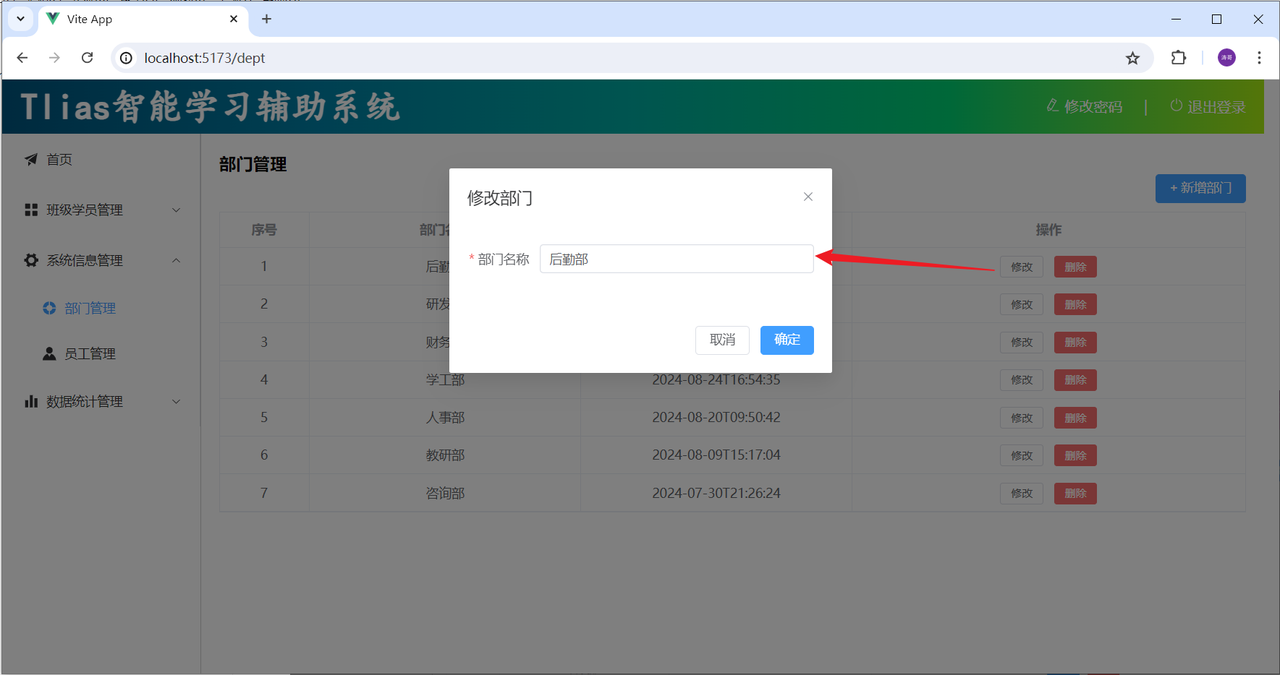

#### 保存修改

由于 新增部门 和 修改部门使用的是同一个Dialog对话框，当前点击 “确定” 按钮的时候，有可能执行的是新增操作，也有可能是修改操作。

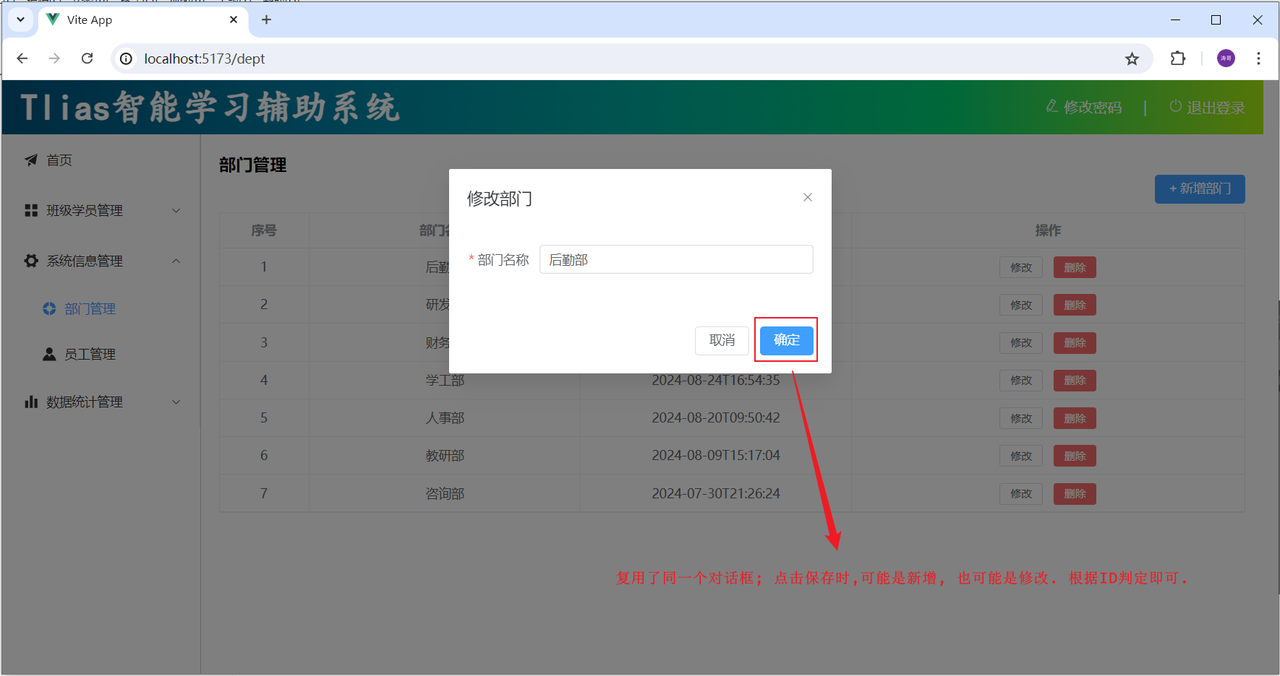

那应该如何辨别到底是新增，还是修改操作呢 ？

其实，我们只需要根据 deptForm 对象的id属性值，来判断即可。 如果没有id，则是新增操作 ；如果有id，则是修改操作。

所以，保存修改功能实现如下：

1). 在 src/api/dept.js 中增加如下修改部门的请求

```javascript
//修改部门
export const updateDeptApi = (data) => request.put('/depts', data)
```

2). 在 src/views/dept/index.vue 中引入上述函数，并完善(修改) save 函数的逻辑

```javascript
import { queryAllApi, addDeptApi, queryInfoApi, updateDeptApi } from '@/api/dept'
```

```javascript
// 提交表单
const save = async () => {
  await deptFormRef.value.validate(async valid => {
    if (!valid) return
    // 提交表单
    let result = null;
    if(deptForm.value.id){
      result = await updateDeptApi(deptForm.value) // 修改
    }else {
      result = await addDeptApi(deptForm.value) // 新增
    } 
    if(result.code){
      ElMessage.success('操作成功')
      // 关闭对话框
      showDialog.value = false
      // 重置表单
      resetForm()
      // 重新加载数据
      queryAll()
    }else {
      ElMessage.error(result.msg)
    }
  })
}
```

最终完整代码如下：

```html
<script setup>
import { ref, onMounted } from 'vue'
import { ElMessage } from 'element-plus'
import { queryAllApi, addDeptApi, queryInfoApi, updateDeptApi } from '@/api/dept'

// 声明列表展示数据
let deptList = ref([])

// 动态加载数据 - 查询部门
const queryAll = async () => {
  const result = await queryAllApi()
  deptList .value = result.data
}

// 钩子函数
onMounted(() => {
  queryAll()
})

const formTitle = ref('')
//新增部门
const add = () => {
  formTitle.value = '新增部门'
  showDialog.value = true
  deptForm.value = {name: ''}
}

// 编辑部门 - 根据ID查询回显数据
const handleEdit = async (id) => {
  console.log(`Edit item with ID ${id}`);
  formTitle.value = '修改部门'
  showDialog.value = true
  deptForm.value = {name: ''}

  const result = await queryInfoApi(id)
  if(result.code){
    deptForm.value = result.data
  }
};

// 删除部门 - 根据ID删除部门
const handleDelete = (id) => {
  console.log(`Delete item with ID ${id}`);
  // 在这里实现删除功能
};

// 新增部门对话框的状态
const showDialog = ref(false)
// 表单数据
const deptForm = ref({name: ''})
// 表单验证规则
const formRules = ref({
  name: [
    { required: true, message: '请输入部门名称', trigger: 'blur' },
    { min: 2, max: 10, message: '长度在 2 到 10 个字符', trigger: 'blur' }
  ]
})

// 表单引用
const deptFormRef = ref(null)

// 重置表单
const resetForm = () => {
  deptFormRef.value.resetFields()
}

// 提交表单
const save = async () => {
  await deptFormRef.value.validate(async valid => {
    if (!valid) return
    // 提交表单
    let result = null;
    if(deptForm.value.id){
      result = await updateDeptApi(deptForm.value) // 修改
    }else {
      result = await addDeptApi(deptForm.value) // 新增
    } 
    if(result.code){
      ElMessage.success('操作成功')
      // 关闭对话框
      showDialog.value = false
      // 重置表单
      resetForm()
      // 重新加载数据
      queryAll()
    }else {
      ElMessage.error(result.msg)
    }
  })
}
</script>

<template>
  <h1>部门管理</h1>

  <!-- 按钮靠页面右侧显示 -->
  <el-button type="primary" @click="add()" style="float: right;"> + 新增部门</el-button> <br><br>

  <!-- 数据展示表格 -->
  <el-table :data="deptList" border style="width: 100%;">
    <el-table-column type="index" label="序号" width="100" align="center"/>
    <el-table-column prop="name" label="部门名称" width="300" align="center"/>
    <el-table-column prop="updateTime" label="最后修改时间" width="300" align="center"/>
    <el-table-column fixed="right" label="操作" align="center">
      <template #default="scope">
        <el-button size="small" @click="handleEdit(scope.row.id)">修改</el-button>
        <el-button size="small" type="danger" @click="handleDelete(scope.row.id)">删除</el-button>
      </template>
    </el-table-column>
  </el-table>

  <!-- 新增部门的对话框 -->
  <el-dialog v-model="showDialog" :title="formTitle" width="30%" @close="resetForm">
    <el-form :model="deptForm" :rules="formRules" ref="deptFormRef">
      <el-form-item label="部门名称" prop="name" label-width="80px">
        <el-input v-model="deptForm.name" autocomplete="off"></el-input>
      </el-form-item>
    </el-form>

    <template #footer>
      <span class="dialog-footer">
        <el-button @click="showDialog = false">取消</el-button>
        <el-button type="primary" @click="save">确定</el-button>
      </span>
    </template>
  </el-dialog>

</template>

<style scoped>

</style>
```

打开浏览器，测试修改员工功能：

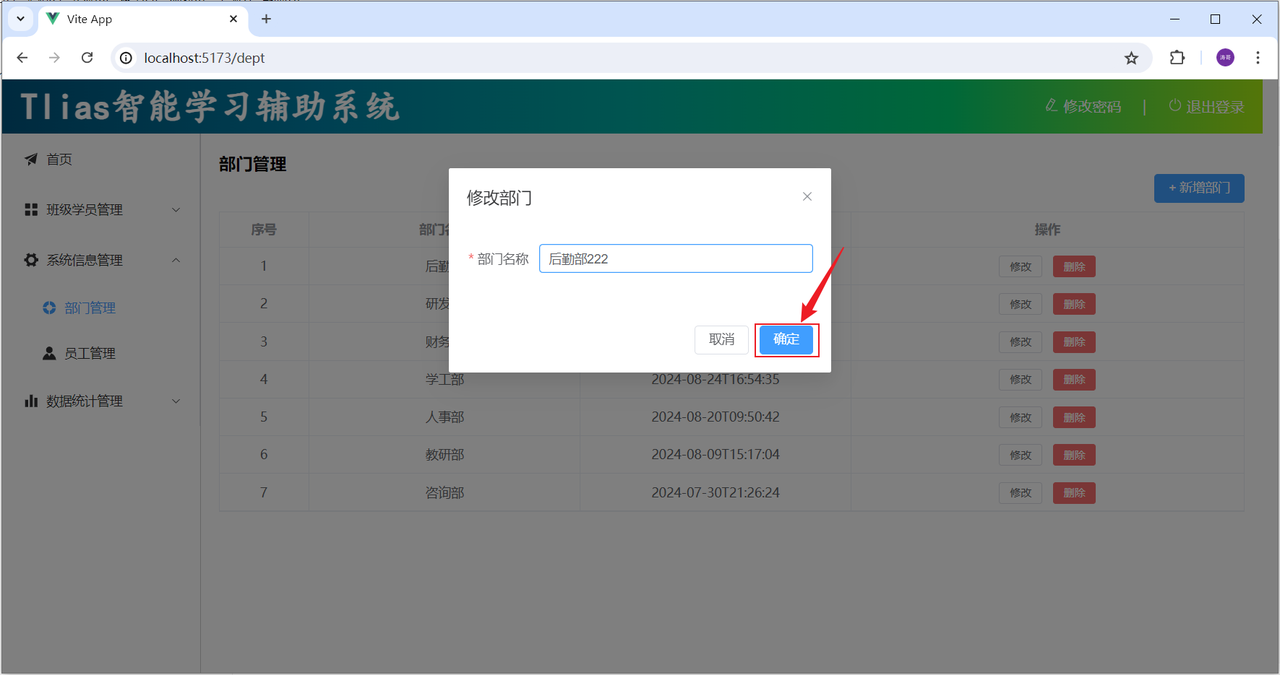

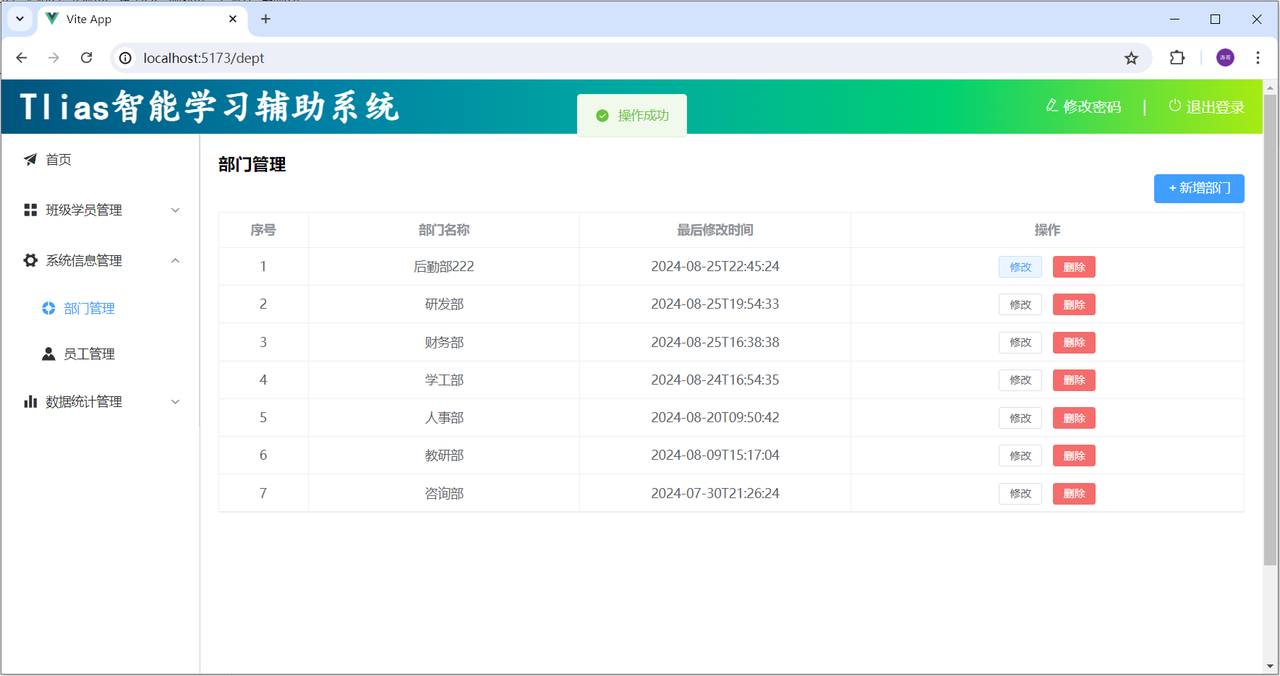

### 删除部门

> **补充｜破坏性操作。** 删除前使用确认框，并在请求期间防止重复点击。删除成功后刷新列表；若后端返回业务失败，应保留当前页面并展示明确原因。

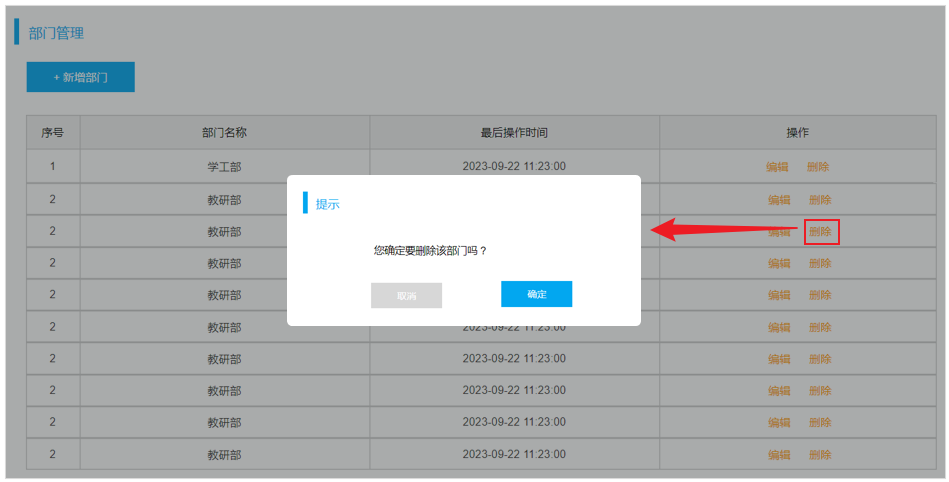

- 点击删除按钮，需要删除当前这条数据，删除完成之后，刷新页面，展示出最新的数据。

- 由于删除是一个比较危险的操作，为避免误操作，通常会在点击删除之后，弹出确认框进行确认。

- Element 组件：ElMessageBox消息弹出框组件

具体操作步骤：

1). 在 src/api/dept.js 中增加如下删除部门的请求

```javascript
//删除部门
export const deleteDeptApi = (id) => request.delete(`/depts?id=${id}`)
```

2). 在 src/views/dept/index.vue 中为 删除 按钮绑定事件

```javascript
 <el-button size="small" type="danger" @click="handleDelete(scope.row.id)">删除</el-button>
```

3). 在 src/views/dept/index.vue  编写根据ID删除数据的函数 。

```javascript
// 删除部门 - 根据ID删除部门
const handleDelete = (id) => {
  console.log(`Delete item with ID ${id}`);
  //删除部门时, 需要弹出一个确认框, 如果是确认, 则删除部门
  ElMessageBox.confirm('此操作将永久删除该部门, 是否继续?', '提示', {
    confirmButtonText: '确定',
    cancelButtonText: '取消',
    type: 'warning'
  }).then(async () => {
    // 删除部门
    const result = await deleteDeptApi(id)
    if(result.code){
      ElMessage.success('删除成功')
      queryAll()
    }
  })
};
```

注意上述，用到了ElementPlus中的 ElMessageBox组件，需要 import 导入进来。代码如下：

```javascript
import { ElMessage, ElMessageBox } from 'element-plus'
```

到目前为止，完整的  src/views/dept/index.vue 代码如下：

```html
<script setup>
import { ref, onMounted } from 'vue'
import { ElMessage, ElMessageBox } from 'element-plus'
import { queryAllApi, addDeptApi, queryInfoApi, updateDeptApi, deleteDeptApi } from '@/api/dept'

// 声明列表展示数据
let deptList= ref([])

// 动态加载数据 - 查询部门
const queryAll = async () => {
  const result = await queryAllApi()
  deptList.value = result.data
}

// 钩子函数
onMounted(() => {
  queryAll()
})

const formTitle = ref('')
//新增部门
const add = () => {
  formTitle.value = '新增部门'
  showDialog.value = true
  deptForm.value = {name: ''}
}

// 编辑部门 - 根据ID查询回显数据
const handleEdit = async (id) => {
  console.log(`Edit item with ID ${id}`);
  formTitle.value = '修改部门'
  showDialog.value = true
  deptForm.value = {name: ''}

  const result = await queryInfoApi(id)
  if(result.code){
    deptForm.value = result.data
  }
};

// 删除部门 - 根据ID删除部门
const handleDelete = (id) => {
  console.log(`Delete item with ID ${id}`);
  //删除部门时, 需要弹出一个确认框, 如果是确认, 则删除部门
  ElMessageBox.confirm('此操作将永久删除该部门, 是否继续?', '提示', {
    confirmButtonText: '确定',
    cancelButtonText: '取消',
    type: 'warning'
  }).then(async () => {
    // 删除部门
    const result = await deleteDeptApi(id)
    if(result.code){
      ElMessage.success('删除成功')
      queryAll()
    }
  })
};

// 新增部门对话框的状态
const showDialog = ref(false)
// 表单数据
const deptForm = ref({name: ''})
// 表单验证规则
const formRules = ref({
  name: [
    { required: true, message: '请输入部门名称', trigger: 'blur' },
    { min: 2, max: 10, message: '长度在 2 到 10 个字符', trigger: 'blur' }
  ]
})

// 表单引用
const deptFormRef = ref(null)

// 重置表单
const resetForm = () => {
  deptFormRef.value.resetFields()
}

// 提交表单
const save = async () => {
  await deptFormRef.value.validate(async valid => {
    if (!valid) return
    // 提交表单
    let result = null;
    if(deptForm.value.id){
      result = await updateDeptApi(deptForm.value) // 修改
    }else {
      result = await addDeptApi(deptForm.value) // 新增
    } 
    if(result.code){
      ElMessage.success('操作成功')
      // 关闭对话框
      showDialog.value = false
      // 重置表单
      resetForm()
      // 重新加载数据
      queryAll()
    }else {
      ElMessage.error(result.msg)
    }
  })
}
</script>

<template>
  <h1>部门管理</h1>

  <!-- 按钮靠页面右侧显示 -->
  <el-button type="primary" @click="add()" style="float: right;"> + 新增部门</el-button> <br><br>

  <!-- 数据展示表格 -->
  <el-table :data="deptList" border style="width: 100%;">
    <el-table-column type="index" label="序号" width="100" align="center"/>
    <el-table-column prop="name" label="部门名称" width="300" align="center"/>
    <el-table-column prop="updateTime" label="最后修改时间" width="300" align="center"/>
    <el-table-column fixed="right" label="操作" align="center">
      <template #default="scope">
        <el-button size="small" @click="handleEdit(scope.row.id)">修改</el-button>
        <el-button size="small" type="danger" @click="handleDelete(scope.row.id)">删除</el-button>
      </template>
    </el-table-column>
  </el-table>

  <!-- 新增部门的对话框 -->
  <el-dialog v-model="showDialog" :title="formTitle" width="30%" @close="resetForm">
    <el-form :model="deptForm" :rules="formRules" ref="deptFormRef">
      <el-form-item label="部门名称" prop="name" label-width="80px">
        <el-input v-model="deptForm.name" autocomplete="off"></el-input>
      </el-form-item>
    </el-form>

    <template #footer>
      <span class="dialog-footer">
        <el-button @click="showDialog = false">取消</el-button>
        <el-button type="primary" @click="save">确定</el-button>
      </span>
    </template>
  </el-dialog>

</template>

<style scoped>

</style>
```

打开浏览器，测试删除员工功能：

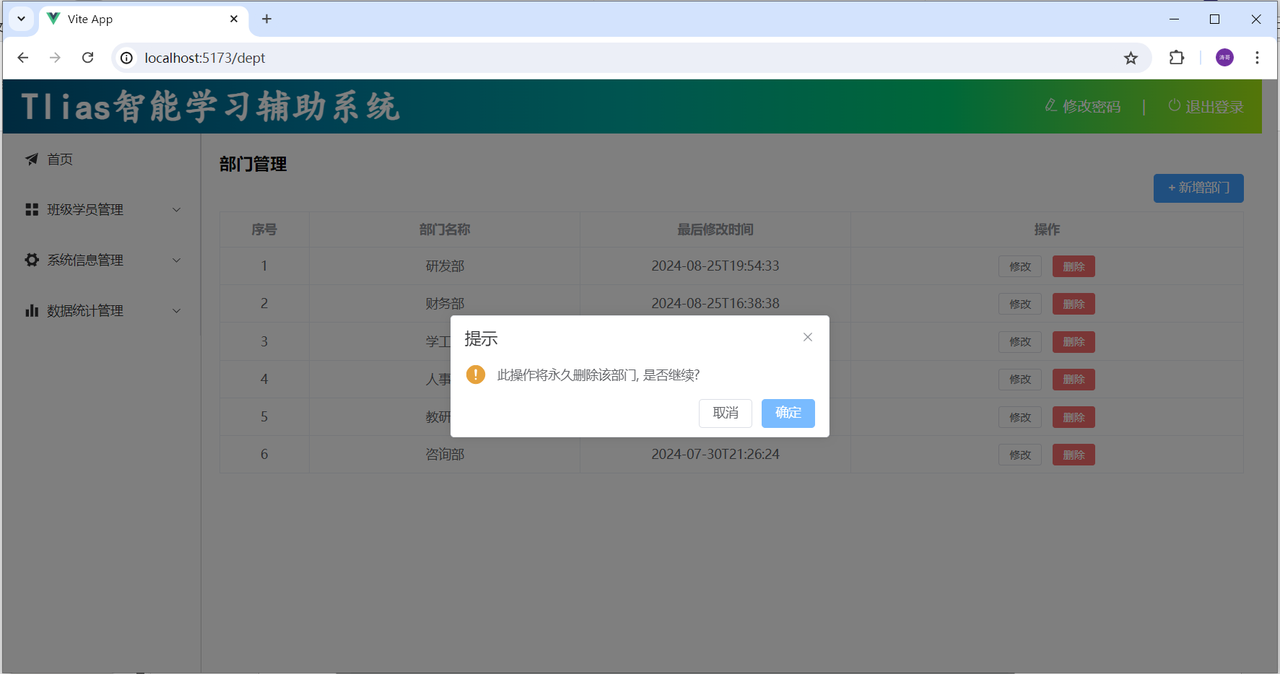

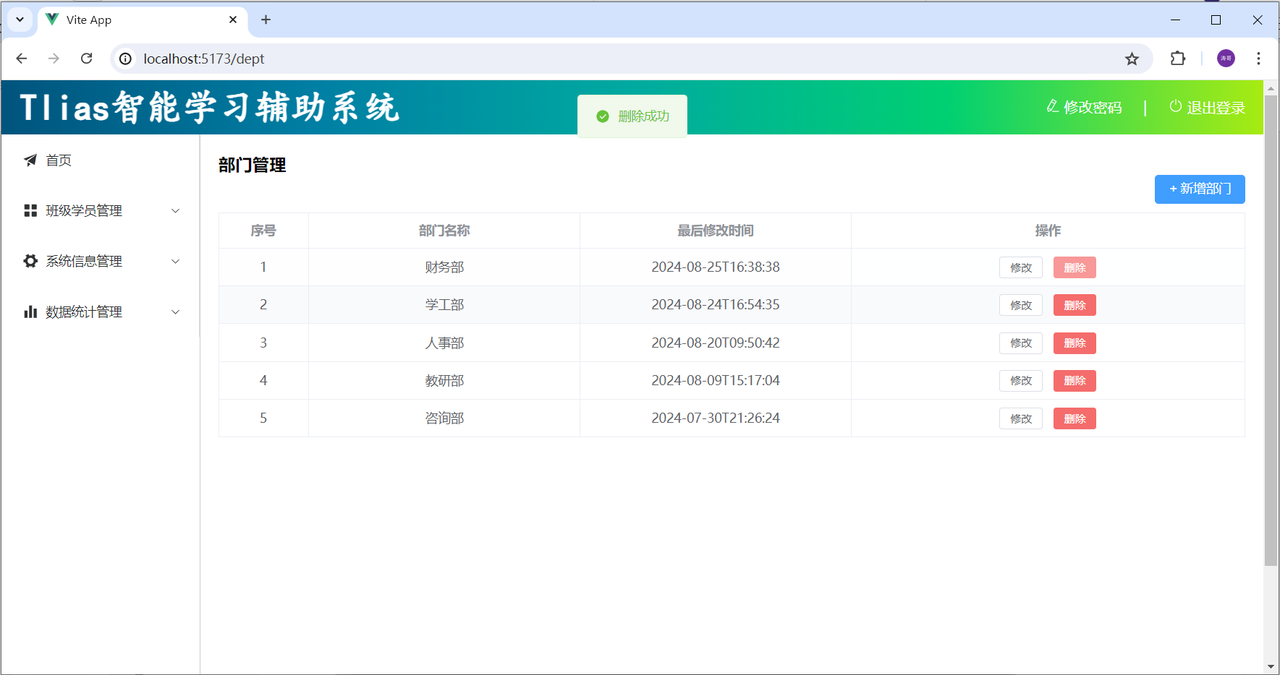

## 复习速查与验收（补充）

| 知识点 | 记忆要点 | 常见误区 |
| --- | --- | --- |
| 前后端分离 | 通过接口文档约定数据格式和协作边界 | 只拆目录，却没有统一响应和错误约定 |
| `router-view` | 渲染当前路由匹配到的组件 | 把业务页面直接写进布局组件 |
| 列表查询 | loading、成功、空数据、异常都要有状态 | 请求失败仍显示旧数据或无限加载 |
| Dialog 表单 | 打开时初始化，关闭时清理，提交前校验 | 新增和编辑共用状态导致数据残留 |
| ElementPlus 校验 | `el-form` 配合 `rules` 和 `validate()` | 只写 rules 却没有绑定 `prop` |
| 异步请求 | await 接口，按响应结构读取数据并处理错误 | 直接假设 `response.data` 就是数组 |
| 删除确认 | 二次确认、禁用重复提交、成功后刷新 | 点击后立即从前端数组删除但后端失败 |

### 跟练验收

1. 访问布局首页和部门路由，刷新浏览器后确认路由仍能正确加载。
2. 部门列表显示加载状态、空状态和错误提示，接口返回数据后正确渲染表格。
3. 新增部门：空表单不能提交，合法数据提交成功后弹窗关闭并刷新列表。
4. 修改部门：打开弹窗能回显名称，修改成功后列表显示新值。
5. 删除部门：确认框取消时不发请求，确认后成功删除并刷新列表。
6. 连续快速点击提交和删除按钮，确认不会产生重复请求或重复提示。
7. 用浏览器 Network 面板核对请求方法、URL、请求体、响应结构和错误状态码。

### 自测问题

- 前后端分离为什么必须维护接口文档？
- `router-link`、`router.push` 和 `router-view` 分别承担什么职责？
- 为什么新增和编辑表单需要在打开、关闭时分别初始化和清理？
- 表单校验通过后，为什么还要处理接口失败？
- 删除成功后为什么通常重新查询列表，而不是只修改本地数组？